# Environment

In [1]:
import os
# Set the environment variable for deterministic behavior
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

In [2]:
!git clone https://github.com/Mage-Knight/efficientvit
%cd /kaggle/working/efficientvit
!conda create -n efficientvit python=3.10 -y
!activate efficientvit # for some reason using conda here stopped working

Cloning into 'efficientvit'...
remote: Enumerating objects: 863, done.
remote: Counting objects: 100% (540/540), done.
remote: Compressing objects: 100% (320/320), done.
remote: Total 863 (delta 301), reused 359 (delta 212), pack-reused 323 (from 1)
Receiving objects: 100% (863/863), 196.03 MiB | 46.68 MiB/s, done.
Resolving deltas: 100% (417/417), done.
/kaggle/working/efficientvit
Retrieving notices: ...working... done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.7.4
  latest version: 24.7.1

Please update conda by running

    $ conda update -n base -c conda-forge conda

Or to minimize the number of packages updated during conda update use

     conda install conda=24.7.1



## Package Plan ##

  environment location: /opt/conda/envs/efficientvit

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-------------

In [3]:
# !conda install -c conda-forge mpi4py openmpi -y

In [4]:
!pip install -r requirements.txt
!pip3 install lightning==2.2.5 torchmetrics==1.4.0.post0 torchvision==0.16.0 torchinfo torch-ema
!pip install -U segmentation-models-pytorch

  Cloning https://github.com/zhijian-liu/torchpack.git (to revision 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5) to /tmp/pip-req-build-1fo17pc0
  Running command git clone --filter=blob:none --quiet https://github.com/zhijian-liu/torchpack.git /tmp/pip-req-build-1fo17pc0
  Running command git rev-parse -q --verify 'sha^3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5'
  Running command git fetch -q https://github.com/zhijian-liu/torchpack.git 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Running command git checkout -q 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Resolved https://github.com/zhijian-liu/torchpack.git to commit 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/alibaba/TinyNeuralNetwork.git to /tmp/pip-req-build-wegxtw3w
  Running command git clone --filter=blob:none --quiet https://github.com/alibaba/TinyNeuralNetwork.git /tmp/pip-req-build-wegxtw3w
  Resolved https://github.com/alibaba/TinyNeuralNetwork.git to commit 202aca86

# Imports

In [5]:
import torch

# Configure PyTorch to use deterministic algorithms
torch.use_deterministic_algorithms(True, warn_only=True) # (involves env. variables, so not used)

import torchvision
import random
import math
# import os
import gc
import cv2
import PIL
import time
import pickle

import torchvision.transforms as transforms
import torchvision.models as models
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
import torchvision.transforms.v2 as transformsv2
import torchvision.transforms.v2.functional as Fv2

from matplotlib.colors import ListedColormap, BoundaryNorm
from transformers import get_cosine_schedule_with_warmup
from tqdm.notebook import tqdm
from copy import deepcopy
from typing import Tuple, Any, Literal
from torch_ema import ExponentialMovingAverage

#EfficientViT
import shutil
from torchinfo import summary
from efficientvit.seg_model_zoo import create_seg_model

# PyTorch
from torch import optim, nn, utils, Tensor
from torchvision.transforms import ToTensor, InterpolationMode, ToPILImage
from torchvision.datasets import ImageFolder
from torchvision.ops import stochastic_depth
from torch.utils.checkpoint import checkpoint
from torch.utils.data import (
    DataLoader, Dataset, Sampler, BatchSampler, ConcatDataset, random_split
)
from torchvision.transforms.functional import to_pil_image
from torchvision.tv_tensors import Mask
from torchvision.io.image import decode_jpeg, read_file

# Lightning
import lightning as L
from lightning.pytorch.callbacks.early_stopping import EarlyStopping
from lightning.pytorch.loggers import TensorBoardLogger
from torchmetrics.classification import (
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassJaccardIndex,
    Dice
)
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.utilities import CombinedLoader

## Transformation testing

In [6]:
# import torchvision.transforms.v2 as transformsv2
# from torchvision.io.image import decode_jpeg, read_file
# import torch
# from torchvision.transforms import ToTensor, InterpolationMode, ToPILImage
# import matplotlib.pyplot as plt
# CENTER_CROP_HEIGHT = 960
# CENTER_CROP_WIDTH = 1920
# # Strong augmentation
# strong_transform_st = transformsv2.Compose([
#     transformsv2.ToDtype(torch.uint8, scale=True),
# #     transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.RandomResizedCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH), # size=(640, 1280),
#                                    scale=(0.5, 1),
#                                    ratio=(1.75, 2.25), # 3./4., 4./3.
#                                    interpolation=InterpolationMode.BICUBIC,
#                                    antialias=True),
#     transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
# ])

# img = read_file("/kaggle/input/indian-driving-dataset/IDD/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# img = decode_jpeg(img, device="cpu")
# plt.imshow(strong_transform_st(img).permute(1,2,0).numpy())

In [7]:
# plt.imshow(img.permute(1,2,0).numpy())

In [8]:
# # Set up the figure and axes for a 3x3 grid
# fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 8))

# # Flatten the axes array for easy indexing
# axes = axes.flatten()

# for i in range(7):
#     # Display each channel as a subplot
#     ax = axes[i]
#     ax.imshow(tsf[i], cmap='gray',interpolation=None)
#     ax.set_title(f'Channel {i+1}')
#     ax.axis('off')  # Hide the axis

# # Turn off the axes for the empty subplot(s)
# for i in range(7, 9):
#     axes[i].axis('off')

# plt.tight_layout()
# plt.show()

In [9]:
# mask1 = torch.randn((7, 32, 64))
# mask2 = torch.randint(1, 5, size=(7,32,64))
# mask3 = torch.tensor([
#     [[1,2,0,1,2,0,1,2],[0,2,0,0,2,0,0,2],[4,0,0,4,0,0,4,0],[4,0,3,4,0,3,4,0],[4,0,3,4,0,3,4,0],[4,0,3,4,0,3,4,0]],
#     [[1,0,0,1,0,0,1,0],[0,3,0,0,3,0,0,3],[3,3,0,3,3,0,3,3],[0,0,3,0,0,3,0,0],[0,0,3,0,0,3,0,0],[4,0,3,4,0,3,4,0]],
#     [[1,0,4,1,0,4,1,0],[0,0,2,0,0,2,0,0],[3,2,0,3,2,0,3,2],[0,2,3,0,2,3,0,2],[0,0,3,0,0,3,0,0],[5,0,3,5,0,3,5,0]],
#     [[1,0,4,1,0,4,1,0],[0,0,2,0,0,2,0,0],[3,0,0,3,0,0,3,0],[0,1,0,0,1,0,0,1],[0,1,0,0,1,0,0,1],[5,1,0,5,1,0,5,1]],
#     [[2,0,0,2,0,0,2,0],[2,0,0,2,0,0,2,0],[2,0,0,2,0,0,2,0],[0,0,0,0,0,0,0,0],[0,0,0,0,0,0,0,0],[5,0,0,5,0,0,5,0]]])
# mask3 = mask3.permute((2,0,1))
# roi = torch.ones((7,32,64))
# tsf = Fv2.rotate(tsf, 25, InterpolationMode.BILINEAR, fill=0)
# tsf

## Install RandAugment implementation for semantic segmentation

In [10]:
class CustomRandAug(nn.Module):
    # Minimum value for posterize (0 in EfficientNet implementation)
    POSTERIZE_MIN = 1
    WARP_PARAMS = {}

    def solarize_add(x, v):
        x = torch.clone(x)  # Clone to avoid modifying the original tensor in-place
        mask = x < 128
        x[mask] = torch.clamp(x[mask] + int(v), 0, 255)
        return x

    OP_FUNCTIONS = {
        # Each op takes an image x and a level v and returns an augmented image.
        # image is in torch format with range [0,1] instead of PIL format with range [0,255]
        "auto_contrast": lambda x, _: Fv2.autocontrast(x),
        "equalize": lambda x, _: Fv2.equalize(x),
        "invert": lambda x, _: Fv2.invert(x),
        "rotate": lambda x, v: Fv2.rotate(x, angle=v, **CustomRandAug.WARP_PARAMS),
        "posterize_inc": lambda x, v: Fv2.posterize(x, bits=max(CustomRandAug.POSTERIZE_MIN, 4 - int(v))),
        "solarize_inc": lambda x, v: Fv2.solarize(x, threshold=1-v),
        "solarize_add": lambda x, v: CustomRandAug.solarize_add(x, v),
        "color_inc": lambda x, v: Fv2.adjust_saturation(x, saturation_factor=1+v),
        "contrast_inc": lambda x, v: Fv2.adjust_contrast(x, contrast_factor=1+v),
        "brightness_inc": lambda x, v: Fv2.adjust_brightness(x, brightness_factor=1+v),
        "sharpness_inc": lambda x, v: Fv2.adjust_sharpness(x, sharpness_factor=1+v),
        "shear_x": lambda x, v: Fv2.affine(x, angle=0, translate=[0, 0], scale=1, shear=[v, 0], **CustomRandAug.WARP_PARAMS),
        "shear_y": lambda x, v: Fv2.affine(x, angle=0, translate=[0, 0], scale=1, shear=[0, v], **CustomRandAug.WARP_PARAMS),
        "trans_x": lambda x, v: Fv2.affine(x, angle=0, translate=[v, 0], scale=1, shear=0, **CustomRandAug.WARP_PARAMS),
        "trans_y": lambda x, v: Fv2.affine(x, angle=0, translate=[0, v], scale=1, shear=0, **CustomRandAug.WARP_PARAMS),
    }

    OP_RANGES = {
        # Ranges for each op in the form of a (min, max, negate).
        "auto_contrast": (0, 1, False),
        "equalize": (0, 1, False),
        "invert": (0, 1, False),
        "rotate": (0.0, 30.0, True),
        "posterize_inc": (0, 4, False),
        "solarize_inc": (0, 255, False),
        "solarize_add": (0, 110, False),
        "color_inc": (0, 0.9, True), #
        "contrast_inc": (0, 0.9, True),
        "brightness_inc": (0, 0.9, True),
        "sharpness_inc": (0, 0.9, True),
        "shear_x": (0.0, math.degrees(math.atan(0.3)), True), # previous range (0.0, 0.3)
        "shear_y": (0.0, math.degrees(math.atan(0.3)), True),
        "trans_x": (0.0, 0.45, True),
        "trans_y": (0.0, 0.45, True),
    }

    RANDAUG_OPS = [
        # RandAugment list of operations using "increasing" transforms.
        # Affine operations turned off due to usage of cutmix and classmix
        "auto_contrast",
        "equalize",
        #"invert",
        "posterize_inc",
        "solarize_inc",
        "solarize_add",
        "color_inc",
        "contrast_inc",
        "brightness_inc",
        "sharpness_inc"
    ]
    
    RANDAUG_OPS_AFFINE = [
        # RandAugment list of operations using "increasing" transforms.
        "auto_contrast",
        "equalize",
        #"invert",
        "rotate",
        "posterize_inc",
        "solarize_inc",
        "solarize_add",
        "color_inc",
        "contrast_inc",
        "brightness_inc",
        "sharpness_inc",
        "shear_x",
        "shear_y",
        "trans_x",
        "trans_y",
    ]

    AFFINE_OPS = [
        "rotate","shear_x","shear_y","trans_x","trans_y"
    ]
    
    def __init__(self, use_affine=True, magnitude=0.9, magnitude_std=0.05, n_ops=2, prob=0.5,
                 fill=(128, 128, 128), ignore_value=26, mask_format='discrete'):
        super().__init__()
        if use_affine:
            self.aug_ops_list = CustomRandAug.RANDAUG_OPS_AFFINE
        else:
            self.aug_ops_list = CustomRandAug.RANDAUG_OPS

        if mask_format!="discrete" and mask_format!="logits":
            raise Exception(f"Unknown mask format: {mask_format}")

        self.mask_format = mask_format
        self.magnitude = magnitude
        self.magnitude_std = magnitude_std
        self.n_ops = n_ops
        self.prob = prob
        self.fill = fill
        self.ignore_value = ignore_value

    def forward(self, *args): # possible *args structure: 
        images = args[0]      # - (mandatory) images
        if len(args) >= 2:    # - (optional) masks
            masks = args[1]   # - (possible if mask_format=="discrete") pixel_confidence
        if len(args) == 3:    # - (will be added automatically if mask_format=="logits") roi_mask
            pix_conf = args[2]
            assert isinstance(pix_conf, Mask), "The received pix_conf tensor is not of tv_tensors.Mask type"
            assert images.device == pix_conf.device, f"Images and pix_conf are not on the same device ({images.device} and {pix_conf.device})"
        elif len(args) > 3:
            raise Exception(f"Unsupported input length: {len(args)}")
        assert isinstance(masks, Mask), "The received mask tensor is not of tv_tensors.Mask type"
        assert images.device == masks.device, f"Images and masks are not on the same device ({images.device} and {masks.device})"
        
        self.overall_device = images.device
        if len(args) != 3:
            images, masks = self.rand_augment_both(images, masks)
        else:
            images, masks, pix_conf = self.rand_augment_both(images, masks, pix_conf)
    
        if len(args) == 3:
            return images.to(self.overall_device), Mask(masks).to(self.overall_device) , Mask(pix_conf).to(self.overall_device)
        elif self.mask_format != "logits":
            return images.to(self.overall_device), Mask(masks).to(self.overall_device)
        else:
            return images.to(self.overall_device), Mask(masks).to(self.overall_device), Mask(self.roi_mask).to(self.overall_device)

    def rand_augment_both(self, images, *args):
        """
        Applies random augmentation to an image.
        Modified implementation from https://github.com/RolandGao/RegSeg/blob/main/augment.py#L141.
        Automatically uses 'inc1', which means that it is implemented in such way, that severity
        of all augmentations increase with the magnitude. Also magnitude is in range(0,1) instead of
        range(0,10) like in timm library implementation.
        """

        batch_size = images.shape[0]
        if self.magnitude_std > 0:  # Add random magnitude option
            magnitude = np.clip(np.random.normal(self.magnitude, self.magnitude_std, batch_size), 0, 1)
        else:
            magnitude = np.full(batch_size, magnitude)

        if len(args) >= 1:
            masks = args[0]
        if len(args) == 2:
            pix_conf = args[1]
            
        if self.mask_format=="logits":
            self.roi_mask = torch.ones(
                tuple(np.array(masks.shape)[[0, 2, 3]])
            ).to(self.overall_device)
        
        for i in range(batch_size):
            for aug in random.sample(self.aug_ops_list, int(self.n_ops)):
                if self.mask_format == "logits":
                    images[i], masks[i], self.roi_mask[i] = self.apply_op_both(
                        (images[i], masks[i], self.roi_mask[i]), aug, magnitude[i]
                    )
                elif len(args) == 2:
                    images[i], masks[i], pix_conf[i] = self.apply_op_both(
                        (images[i], masks[i], pix_conf[i]), aug, magnitude[i]
                    )
                else:
                    images[i], masks[i] = self.apply_op_both((images[i], masks[i]), aug, magnitude[i])
        if len(args) == 2:
            return images, masks, pix_conf
        else:
            return images, masks
    
    def apply_op_both(self, inputs, aug, magnitude):
        """Apply the selected op to image with given probability and magnitude."""
        # The magnitude is converted to an absolute value v for an op (some ops use -v or v)
        assert 0 <= magnitude <= 1
        assert aug in CustomRandAug.OP_RANGES and aug in CustomRandAug.RANDAUG_OPS_AFFINE, "unknown op " + aug
        if len(inputs)==2:
            img, mask = inputs
        elif len(inputs)==3:
            img, mask, supplem_mask = inputs
        else:
            raise Exception(f"Unsupported input length: {len(inputs)}")
        if self.prob < 1 and random.random() > self.prob:
            if len(inputs)==2:
                return img, mask
            else:
                return img, mask, supplem_mask
        else:
            min_v, max_v, negate = CustomRandAug.OP_RANGES[aug]
            v = magnitude * (max_v - min_v) + min_v
            v = -v if negate and random.random() > 0.5 else v
            # Image augmentation
            CustomRandAug.WARP_PARAMS["fill"] = self.fill
            CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.BILINEAR
            img = CustomRandAug.OP_FUNCTIONS[aug](img, v)
            if aug in CustomRandAug.AFFINE_OPS:
                if self.mask_format!="logits":
                    # Discrete mask augmentation
                    CustomRandAug.WARP_PARAMS["fill"] = self.ignore_value
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                    mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(mask), v)
                    if len(inputs)==3:
                        # Confidence augmentation
                        CustomRandAug.WARP_PARAMS["fill"] = 0
                        CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                        supplem_mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(supplem_mask), v) # pix_conf
                else:
                    # Logit mask augmentation
                    CustomRandAug.WARP_PARAMS["fill"] = 0
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.BILINEAR
                    mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(mask), v)
                    # Region of interest mask augmentation
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                    supplem_mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(supplem_mask), v) # roi_mask
            if self.mask_format!="logits" and len(inputs) == 3:
                return img, mask, supplem_mask
            else:
                return img, mask

# Const variables

In [11]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE_ST = 10 # 32 -> 16 -> 10 (last)
BATCH_SIZE_SST = 2 # 8 / 6 -> 4 -> 2 (last)
UNLAB_MULT = 4 # 4 / 5 -> 4 (last)
MEAN_TRN = np.load("/kaggle/input/efficientvit-checkpoint/channel_mean_data_ii_1_9lab.npy")
STD_TRN = np.load("/kaggle/input/efficientvit-checkpoint/channel_std_data_ii_1_9lab.npy")
RAND_CONST = 10
# NEW_HEIGHT, NEW_WIDTH = 224, 448
# NEW_HEIGHT_FT, NEW_WIDTH_FT = 288, 576
# size 512 x 1024 takes approx. 10 minutes per epoch
CENTER_CROP_HEIGHT = 960
CENTER_CROP_WIDTH = 1920
NEW_HEIGHT, NEW_WIDTH = 416, 832 # 608, 1216 # 416, 832   # 256, 512 
NEW_HEIGHT_FT, NEW_WIDTH_FT = 416, 832  # 256, 512
DECAY_VAL = 0.99 # 0.9999 if one teacher

LOW_LEVEL_MAPPING = [
    'road',
    'parking/drivable fallback',
    'sidewalk',
    'non-drivable fallback/rail track',
    'person/animal',
    'rider',
    'motorcycle',
    'bicycle',
    'autorickshaw',
    'car',
    'truck',
    'bus',
    'caravan/trailer/vehicle fallback',
    'curb',
    'wall',
    'fence',
    'guard rail',
    'billboard',
    'traffic sign',
    'traffic light',
    'pole/polegroup',
    'obs-str-bar-fallback',
    'building',
    'bridge/tunnel',
    'vegetation',
    'sky/fallback background',
    'unlabeled/out of roi' # label 26, not used during training
]
HIGH_LEVEL_MAPPING = [
    'drivable',
    'non-drivable',
    'living things',
    'vehicles',
    'road side objects',
    'far objects',
    'sky',
    'unlabeled/out of roi' # label 7 not used during training
]
MIDDLE_LEVEL_MAPPING = [
    'road',
    'other drivable',
    'sidewalk',
    'other non-drivable',
    'living being',
    'rider',
    'small vehicle',
    'medium vehicle',
    'large vehicle',
    'edge boundary',
    'barrier',
    'information road side object',
    'support structures',
    'large infrastructure',
    'vegetation',
    'sky',
    'unlabeled/out of roi' # label 16 not used during training
]
HIGH_NUM_CLASSES = len(HIGH_LEVEL_MAPPING) - 1
MIDDLE_NUM_CLASSES = len(MIDDLE_LEVEL_MAPPING) - 1
LOW_NUM_CLASSES = len(LOW_LEVEL_MAPPING) - 1

# # Define a list of distinct colors (excluding black and white)
# colors = [
#     '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', 
#     '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#1a55FF', '#55a8ff', 
#     '#6e6e6e', '#85a3e0', '#296e01', '#28ed28', '#848484', '#adf802', 
#     '#ffaa00', '#d35400', '#c0392b', '#bdc3c7', '#7f8c8d', '#999999', 
#     '#f39c12', '#f5b041', '#dc7633', '#6e2c00'
# ]

CURRENT_LEVEL_MAPPING = HIGH_LEVEL_MAPPING
CURRENT_NUM_CLASSES = len(CURRENT_LEVEL_MAPPING) - 1
CURRENT_HIERARCHY_STR = "high"
ABUNDANT_CLASSES = torch.Tensor([0, 6])
# ABUNDANT_CLASSES = torch.Tensor([0, 1, 15])

colors = [
    "#33cc33", # light green
    "#663300", # brown
    "#cc0000", # red
    "#ffff00", # yellow
    "#660066", # purple
    "#1f77b4", # blue
    "#66ffff", # light blue
    "#808080", # gray,
    "#009933", # green
    "#cc0099", # pink
    "#ffffff", # white
    "#000066", # dark blue
    "#ccff99", # sand
    "#00ff00", # lime
    "#800000", # maroon
    "#660035", # dark purple
    "#ff99cc", # light pink
    
]

# Ensure there are enough colors for each class
assert len(colors) >= len(CURRENT_LEVEL_MAPPING), "Not enough colors for each class"

def hex_to_rgb(hex_color):
    return tuple(int(hex_color[i:i+2], 16) / 255. for i in (1, 3, 5))  # skip the '#'

RGB_COLORS = [hex_to_rgb(color) for color in colors]

# Create a colormap from the list of colors
CURRENT_CMAP = ListedColormap(RGB_COLORS[:len(CURRENT_LEVEL_MAPPING)])
current_boundaries = np.arange(-0.5, len(CURRENT_LEVEL_MAPPING) + 0.5, 1)  # Setting boundaries between labels
CURRENT_NORM = BoundaryNorm(current_boundaries, CURRENT_CMAP.N, clip=True)  # Create the norm

LOW_CMAP = plt.get_cmap('tab20', LOW_NUM_CLASSES + 1)
boundaries_low = np.arange(-0.5, len(LOW_LEVEL_MAPPING) + 0.5, 1)  # Setting boundaries between labels
LOW_NORM = BoundaryNorm(boundaries_low, LOW_CMAP.N, clip=True)  # Create the norm

CLASS_WEIGHTS = torch.tensor(np.load("/kaggle/input/efficientvit-checkpoint/class_weights.npy"))

# Reproducibility

In [12]:
# Worker initialization function for data loaders (simplest approach)
def seed_worker(worker_id):
    worker_seed = (torch.initial_seed() + worker_id) % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g_train_l_st = torch.Generator().manual_seed(RAND_CONST)
g_train_l_sst = torch.Generator().manual_seed(RAND_CONST + 1)
g_train_ul_i = torch.Generator().manual_seed(RAND_CONST + 2)
g_train_ul_ii = torch.Generator().manual_seed(RAND_CONST + 3)
g_val = torch.Generator().manual_seed(RAND_CONST + 4)
g_test = torch.Generator().manual_seed(RAND_CONST + 5)
g_train_ul_full = torch.Generator().manual_seed(RAND_CONST + 6)

# Set python seed
random.seed(RAND_CONST)
# Set numpy seed
np.random.seed(RAND_CONST)
# Seed the RNG for all devices (both CPU and CUDA)
torch.manual_seed(RAND_CONST)
torch.cuda.manual_seed_all(RAND_CONST)
# Force cuDNN to deterministically select an algorithm
# *possibly at the cost of reduced performance
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Model definition

In [13]:
# semantic segmentation
from efficientvit.models.efficientvit.seg import SegHead
from efficientvit.models.efficientvit.seg import EfficientViTSeg
from efficientvit.models.efficientvit.backbone import efficientvit_backbone_b1, EfficientViTBackbone, EfficientViTLargeBackbone
from efficientvit.models.utils import build_kwargs_from_config

class EfficientViTSegMod(EfficientViTSeg):
    def __init__(self, backbone: EfficientViTBackbone or EfficientViTLargeBackbone, head: SegHead) -> None:
        super().__init__(backbone, head)
        self.enlarge = nn.Upsample(scale_factor=(8,8), mode='bicubic')
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feed_dict = self.backbone(x)
        feed_dict = self.head(feed_dict)
#         return feed_dict["segout"]
        return self.enlarge(feed_dict["segout"])

def efficientvit_seg_b1(dataset: str, **kwargs) -> EfficientViTSegMod:
    backbone = efficientvit_backbone_b1(**kwargs)

    if dataset == "cityscapes":
        head = SegHead(
            fid_list=["stage4", "stage3", "stage2"],
            in_channel_list=[256, 128, 64],
            stride_list=[32, 16, 8],
            head_stride=8,
            head_width=64,
            head_depth=3,
            expand_ratio=4,
            middle_op="mbconv",
            final_expand=4,
            n_classes=CURRENT_NUM_CLASSES,
            **build_kwargs_from_config(kwargs, SegHead),
        )
    else:
        raise NotImplementedError
    model = EfficientViTSegMod(backbone, head)
    return model

from efficientvit.models.efficientvit import (
    EfficientViTSeg,
    efficientvit_seg_b0,
    efficientvit_seg_b1,
    efficientvit_seg_b2,
#     efficientvit_seg_b3,
#     efficientvit_seg_l1,
#     efficientvit_seg_l2,
)
from efficientvit.models.nn.norm import set_norm_eps
from efficientvit.models.utils import load_state_dict_from_file

__all__ = ["create_seg_model"]

REGISTERED_SEG_MODEL: dict[str, dict[str, str]] = {
    "cityscapes": {
        "b0": "assets/checkpoints/seg/cityscapes/b0.pt",
        "b1": "assets/checkpoints/seg/cityscapes/b1.pt",
        "b2": "assets/checkpoints/seg/cityscapes/b2.pt",
#         "b3": "assets/checkpoints/seg/cityscapes/b3.pt",
        ################################################
#         "l1": "assets/checkpoints/seg/cityscapes/l1.pt",
#         "l2": "assets/checkpoints/seg/cityscapes/l2.pt",
    },
#     "ade20k": {
#         "b1": "assets/checkpoints/seg/ade20k/b1.pt",
#         "b2": "assets/checkpoints/seg/ade20k/b2.pt",
#         "b3": "assets/checkpoints/seg/ade20k/b3.pt",
        ################################################
#         "l1": "assets/checkpoints/seg/ade20k/l1.pt",
#         "l2": "assets/checkpoints/seg/ade20k/l2.pt",
#     },
}


def create_seg_model(
    name: str, dataset: str, pretrained=True, weight_url: str or None = None, **kwargs
) -> EfficientViTSegMod:
    model_dict = {
        "b0": efficientvit_seg_b0,
        "b1": efficientvit_seg_b1,
        "b2": efficientvit_seg_b2,
#         "b3": efficientvit_seg_b3,
        #########################
#         "l1": efficientvit_seg_l1,
#         "l2": efficientvit_seg_l2,
    }

    model_id = name.split("-")[0]
    if model_id not in model_dict:
        raise ValueError(f"Do not find {name} in the model zoo. List of models: {list(model_dict.keys())}")
    else:
        model = model_dict[model_id](dataset=dataset, **kwargs)

    if model_id in ["l1", "l2"]:
        set_norm_eps(model, 1e-7)

    if pretrained:
        weight_url = weight_url or REGISTERED_SEG_MODEL[dataset].get(name, None)
        if weight_url is None:
            raise ValueError(f"Do not find the pretrained weight of {name}.")
        else:
            weight = load_state_dict_from_file(weight_url)
            model.load_state_dict(weight)
    return model

# Model creation
model_b1 = create_seg_model(
  name="b1", dataset="cityscapes", weight_url="assets/checkpoints/seg/cityscapes/b1.pt"
)
model_b1.head = SegHead(
    fid_list=["stage4", "stage3", "stage2"],
    in_channel_list=[256, 128, 64],
    stride_list=[32, 16, 8],
    head_stride=8,
    head_width=64,
    head_depth=3,
    expand_ratio=4,
    middle_op="mbconv",
    final_expand=4,
    n_classes=CURRENT_NUM_CLASSES
)


class StochasticDepth(nn.Module):
    def __init__(self, module: nn.Module, p: float, mode: str = "batch") -> None:
        super().__init__()
        self.p = p
        self.mode = mode
        self.module = module
        self.sub_mode = True

    def forward(self, x: Tensor) -> Tensor:
        return stochastic_depth(self.module(x), self.p, self.mode, self.training and self.sub_mode)


def add_stohastic_depth(model, blocks_modified, p_L=0.1):
#     for layer, block in enumerate(blocks_modified):
#         p_l = (layer + 1) / len(blocks_modified) * (1 - p_L)
#         blocks_modified[layer] = StochasticDepth(block, p=p_l)

    for layer, block_path in enumerate(blocks_modified):
        p_l = (layer + 1) / len(blocks_modified) * (1 - p_L)
        # Get the block using the attribute path
        block = eval(f"model.{block_path}")
        # Create the StochasticDepthBlock
        stochastic_block = StochasticDepth(block, p=p_l)
        # Set the new block back to the model
        exec(f"model.{block_path} = stochastic_block")


def set_sub_mode(model: nn.Module, value: bool) -> None:
    def _set_sub_mode(module: nn.Module) -> None:
        if isinstance(module, StochasticDepth):
            module.sub_mode = value

    model.apply(_set_sub_mode)    


def load_weights_with_modified_blocks(model, checkpoint_path, blocks_modified):
    # Load the checkpoint
    checkpoint = torch.load(checkpoint_path)
    state_dict = checkpoint['model_state_dict']
    
    # Get the state dictionary of the modified model
    new_state_dict = model.state_dict()
    
    # Create a set of keys for blocks_modified
    modified_keys = set()
    for block_str in blocks_modified:
        block = eval(f"model.{block_str}")
        for name, _ in block.named_parameters():
            modified_keys.add(f"{block._get_name()}.{name}")
    
    # Iterate over the keys in the checkpoint's state dictionary
    for key in state_dict:
        # Check if the key belongs to blocks_modified
        if key in modified_keys:
            # Modify the key to include "module"
            new_key = key.replace(block._get_name(), f"{block._get_name()}.module")
            if new_key in new_state_dict:
                new_state_dict[new_key] = state_dict[key]
            else:
                raise Exception(f"Weights with key value: {new_key} weren't found in the model")
        else:
            # Load the weight as usual
            if key in new_state_dict:
                new_state_dict[key] = state_dict[key]
    
    # Load the modified state dictionary into the model
    model.load_state_dict(new_state_dict)

blocks_modified_paths = [
    'backbone.input_stem.op_list[1].main',
    'backbone.stages[0].op_list[1].main',
    'backbone.stages[1].op_list[1].main',
    'backbone.stages[1].op_list[2].main',
    'backbone.stages[2].op_list[1].context_module.main',
    'backbone.stages[2].op_list[1].local_module.main',
    'backbone.stages[2].op_list[2].context_module.main',
    'backbone.stages[2].op_list[2].local_module.main',
    'backbone.stages[2].op_list[3].context_module.main',
    'backbone.stages[2].op_list[3].local_module.main',
    'backbone.stages[3].op_list[1].context_module.main',
    'backbone.stages[3].op_list[1].local_module.main',
    'backbone.stages[3].op_list[2].context_module.main',
    'backbone.stages[3].op_list[2].local_module.main',
    'backbone.stages[3].op_list[3].context_module.main',
    'backbone.stages[3].op_list[3].local_module.main',
    'backbone.stages[3].op_list[4].context_module.main',
    'backbone.stages[3].op_list[4].local_module.main',
]

# Add stohastic depth to backbone
# add_stohastic_depth(model_b1, blocks_modified_paths, p_L=0.1)

In [14]:
model_b1

EfficientViTSeg(
  (backbone): EfficientViTBackbone(
    (input_stem): OpSequential(
      (op_list): ModuleList(
        (0): ConvLayer(
          (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (act): Hardswish()
        )
        (1): ResidualBlock(
          (main): DSConv(
            (depth_conv): ConvLayer(
              (conv): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (act): Hardswish()
            )
            (point_conv): ConvLayer(
              (conv): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
          )
          (shortcut): Identity

In [15]:
batch_size = 1
summary(model_b1, input_size=(1, 3, 416, 832))

Layer (type:depth-idx)                                            Output Shape              Param #
EfficientViTSeg                                                   [1, 7, 52, 104]           --
├─EfficientViTBackbone: 1-1                                       [1, 256, 13, 26]          --
│    └─OpSequential: 2-1                                          [1, 16, 208, 416]         --
│    │    └─ModuleList: 3-1                                       --                        928
│    └─ModuleList: 2-2                                            --                        --
│    │    └─OpSequential: 3-2                                     [1, 32, 104, 208]         13,888
│    │    └─OpSequential: 3-3                                     [1, 64, 52, 104]          86,528
│    │    └─OpSequential: 3-4                                     [1, 128, 26, 52]          756,864
│    │    └─OpSequential: 3-5                                     [1, 256, 13, 26]          3,785,728
├─SegHead: 1-2          

In [16]:
# !python demo_seg_model.py --image_path assets/fig/068726_leftImg8bit.png --dataset cityscapes --crop_size 1024 --model b1

# Dataset

In [17]:
class IDD_Dataset(Dataset):
    def __init__(self, root_dir, parts = ['I', 'II'], splits = ['train', 'val'], hierarchy="low"):
        self.root_dir_img = root_dir + "/IDD"
        self.root_dir_mask = root_dir + ("/IDD" if hierarchy == "low" else f"/{hierarchy}_level_labels")
        self.data_paths = []
        self.data_shapes = []
        self.is_test_set = splits == ['test']
        self.hierarchy = hierarchy

        for part in parts:
            if not self.is_test_set:
                for split in splits:
                    mask_dir = os.path.join(
                        self.root_dir_mask,
                       f'idd_seg_part_{part}_gtFine' + f"_{hierarchy}" if hierarchy!="low" else "",
                        split
                    )
                    # img_dir = os.path.join(root_dir, f'idd_seg_part_{part}_leftImg8bit', split)
                    for folder_num in os.listdir(mask_dir):
                        for mask_file in os.listdir(os.path.join(mask_dir, folder_num)):
                            if mask_file.endswith('_gtFine_polygons.npz'):
                                starting_part = mask_file.replace('_gtFine_polygons.npz', '')
                                # Obtaining image shape
                                img_path = os.path.join(
                                    self.root_dir_img,
                                    f'idd_seg_part_{part}_leftImg8bit',
                                    split,
                                    folder_num,
                                    f'{starting_part}_leftImg8bit.jpg'
                                )
                                img = read_file(img_path)
                                img = decode_jpeg(img, device="cpu")
                                (height, width) = img.shape[1:] # Get the image size
#                                 img = PIL.Image.open(img_path)
#                                 width, height = img.size # Get the image size
                                self.data_shapes.append((height, width))
                                self.data_paths.append((part, split, folder_num, starting_part))
            else:
                for split in splits:
                    img_dir = os.path.join(
                        self.root_dir_img,
                        f'idd_seg_part_{part}_leftImg8bit',
                        split
                    )
                    for folder_num in os.listdir(img_dir):
                        for img_file in os.listdir(os.path.join(img_dir, folder_num)):
                            if img_file.endswith('_leftImg8bit.jpg'):
                                starting_part = img_file.replace('_leftImg8bit.jpg', '')
                                # Obtaining image shape
                                img_path = os.path.join(
                                    self.root_dir_img,
                                    f'idd_seg_part_{part}_leftImg8bit',
                                    split,
                                    folder_num,
                                    f'{starting_part}_leftImg8bit.jpg'
                                )
                                img = read_file(img_path)
                                img = decode_jpeg(img, device="cpu")
                                (height, width) = img.shape[1:] # Get the image size
#                                 img = PIL.Image.open(img_path)
#                                 width, height = img.size # Get the image size
                                self.data_shapes.append((height, width))
                                self.data_paths.append((part, split, folder_num, starting_part))

        self.data_shapes = np.array(self.data_shapes)

    def __len__(self):
        return len(self.data_paths)

    def __getitem__(self, idx):
        part, split, folder_num, starting_part = self.data_paths[idx]

        if not self.is_test_set:
            mask_path = os.path.join(
                self.root_dir_mask,
                f'idd_seg_part_{part}_gtFine' + f"_{self.hierarchy}" if self.hierarchy!="low" else "",
                split,
                folder_num,
                f'{starting_part}_gtFine_polygons.npz'
            )
            mask = np.load(mask_path)['masks']
        else:
            mask = np.array([-1])
        
        img_path = os.path.join(
            self.root_dir_img,
            f'idd_seg_part_{part}_leftImg8bit',
            split,
            folder_num,
            f'{starting_part}_leftImg8bit.jpg'
        )
        img = read_file(img_path)
        img = decode_jpeg(img, device="cpu")
        # Return Image: C x H x W, Mask: H x W
        return img, Mask(torch.from_numpy(mask))
        # Changed approach below to decoding jpeg because of time consumption
#         img = PIL.Image.open(img_path) 
#         img = np.array(img)
        # Return Image: C x H x W, Mask: H x W
#         return torch.from_numpy(img).permute((2,0,1)), Mask(torch.from_numpy(mask))
    
    def image_shapes_quantity(self, check_idx="all", print_flag=False):
        indices_by_shape = {}
        if type(check_idx)!=str:
            check_idx = np.array(check_idx)
        for idx, (height, width) in enumerate(self.data_shapes):
            if type(check_idx)==str and check_idx=="all":
                indices_by_shape.setdefault((height, width), []).append(idx)
            elif idx in check_idx:
                renumb_idx = np.where(check_idx == idx)[0][0]
                indices_by_shape.setdefault((height, width), []).append(renumb_idx)

        for key, elements in indices_by_shape.items():
            indices_by_shape[key] = np.array(elements)

        if not print_flag:
            return indices_by_shape
        else:
            for key, elements in indices_by_shape.items():
                print(f"Amount (ratio) of {key} sized elements: {len(elements)} ({len(elements)/len(self)})")


class SameShapeSampler(Sampler):
    def __init__(self, data_source, batch_size, generator=None):
        self.data_source = data_source
        self.batch_size = batch_size
        self.generator = generator
        self.indices_by_shape = data_source.image_shapes_quantity()

    def __iter__(self):
        all_batches = []
        for _, indices in self.indices_by_shape.items(): # shape not used
            shuffled_indices_idx = torch.randperm(len(indices), generator=self.generator)
            shuffled_indices = indices[shuffled_indices_idx]
            for i in range(0, len(shuffled_indices) - self.batch_size + 1, self.batch_size):
                batch = shuffled_indices[i:i+self.batch_size]
                all_batches.append(batch)

        all_batches = np.array(all_batches)
        shuffled_batches_idx = torch.randperm(all_batches.shape[0], generator=self.generator)
        return iter(all_batches[shuffled_batches_idx,:].flatten())

    def __len__(self):
        return sum((len(indices) - len(indices) % self.batch_size) for indices in self.indices_by_shape.values())


class SameShapeBatchSampler(Sampler):
    def __init__(self, data_source, batch_size, shuffle, drop_last, generator=None):
        self.data_source = data_source
        self.batch_size = batch_size
        self.generator = generator
        self.shuffle = shuffle
        self.drop_last = drop_last
        if isinstance(data_source, IDD_Dataset):
            self.indices_by_shape = data_source.image_shapes_quantity()
        elif isinstance(data_source, torch.utils.data.ConcatDataset):
            cum_data_size = 0
            self.indices_by_shape = {}
            for dataobj in data_source.datasets:
                if isinstance(dataobj, torch.utils.data.Subset):
                    new_idx = dataobj.dataset.image_shapes_quantity(check_idx=dataobj.indices)
                elif isinstance(dataobj, IDD_Dataset):
                    new_idx = dataobj.image_shapes_quantity()
                else:
                    raise Exception(f"Unknown dataobj type: {type(dataobj)}")
                new_idx = {key: value + cum_data_size for key, value in new_idx.items()}
                
                # Update the dictionary
                for key, value in new_idx.items():
                    if key in self.indices_by_shape:
                        common_elements = np.intersect1d(self.indices_by_shape[key], value)
                        if common_elements.size > 0:
                            raise ValueError(f"Duplicate items found for key {key}: {common_elements}")
                        self.indices_by_shape[key] = np.concatenate((self.indices_by_shape[key], value))
                    else:
                        self.indices_by_shape[key] = value

                cum_data_size += len(dataobj)
        elif isinstance(data_source, torch.utils.data.dataset.Subset):
            self.indices_by_shape = data_source.dataset.image_shapes_quantity(check_idx=data_source.indices)
        else:
            raise Exception(f"Unknown data_source type: {type(data_source)}")


    def __iter__(self):
        all_batches = []
        if not self.drop_last:
            resid_batches = []
        for _, indices in self.indices_by_shape.items(): # shape not used
            if self.shuffle:
                shuffled_indices_idx = torch.randperm(len(indices), generator=self.generator)
                indices = indices[shuffled_indices_idx]
            for i in range(0, len(indices) - self.batch_size + 1, self.batch_size):
                batch = indices[i:i+self.batch_size]
                all_batches.append(batch)
            if not self.drop_last:
                resid_batches.append(indices[-int(len(indices) % self.batch_size):])

#         all_batches = np.array(all_batches)
        if self.shuffle:
            shuffled_batches_idx = torch.randperm(len(all_batches), generator=self.generator)
#             all_batches = all_batches[shuffled_batches_idx,:]
            all_batches = [all_batches[i] for i in shuffled_batches_idx]
            if not self.drop_last:
                shuffled_resid_batches_idx = torch.randperm(len(resid_batches), generator=self.generator)
                resid_batches = [resid_batches[i] for i in shuffled_resid_batches_idx]
        
        if not self.drop_last:
            all_batches += resid_batches
#             all_batches = np.vstack((all_batches, resid_batches)) # uncomplete batches go to the end
        
        for batch_idx in range(len(all_batches)):
            yield all_batches[batch_idx]
#             yield all_batches[batch_idx,:]

    def __len__(self):
        if self.drop_last:
            return sum((len(indices) // self.batch_size) for indices in self.indices_by_shape.values())
        else:
            return sum((len(indices) // self.batch_size) + (1 if len(indices) % self.batch_size != 0 else 0) for indices in self.indices_by_shape.values())
            


def apply_model_and_show_results(model, image, new_height, new_width, level_mapping=CURRENT_LEVEL_MAPPING,
                                 cmap=CURRENT_CMAP, norm=CURRENT_NORM, real_mask=None, transform=None):

    # Ensure model is in evaluation mode
    model.eval()
    if transform is None:
        transform = transformsv2.Compose([
            transformsv2.ToDtype(torch.float32, scale=True),
            transformsv2.Resize((NEW_HEIGHT, NEW_WIDTH), antialias=True)
        ])

    if real_mask is not None:
        image, real_mask = transform(image.unsqueeze(0), Mask(real_mask.unsqueeze(0)))
    else:
        image = transform(image.unsqueeze(0))

    original_height, original_width = image.shape[2:4]
    # Resize image
#     image_resized = transforms.functional.resize(
#         input_image.squeeze(0), size=(new_height, new_width),
#         interpolation=InterpolationMode.BICUBIC,
#         antialias=False
#     ) # shape: C x H x W

    # Apply model to image
    with torch.no_grad():
        logits = model(image.to(DEVICE)) # add batch_size=1

    # Resize predicted mask back to original size
    logits = Fv2.resize(
        logits.detach().cpu()[0], size=(original_height, original_width),
        interpolation=InterpolationMode.BICUBIC,
        antialias=True
    ) # shape: num_classes x H x W

    # Get the predicted class for each pixel
    predicted = torch.argmax(logits, 0).numpy() # shape: H x W

    # Display the overlay
    fig, axs = plt.subplots(3 if real_mask is not None else 2, 1, figsize=(25, 15))

    image = image.squeeze(0)
    axs[0].imshow(image.permute((1,2,0)))
    axs[0].set_title('Image')
    axs[0].axis('off')
    
    axs[1].imshow(image.permute((1,2,0)), cmap='gray', interpolation='none')
    axs[1].imshow(predicted, cmap=cmap, norm=norm, alpha=0.5, interpolation='none')
    axs[1].set_title('Predicted mask')
    axs[1].axis('off')

    if real_mask is not None:
        axs[2].imshow(image.permute((1,2,0)), cmap='gray', interpolation='none')
        axs[2].imshow(real_mask.squeeze((0,1)), cmap=cmap, norm=norm, alpha=0.5, interpolation='none')
        axs[2].set_title('Real mask')
        axs[2].axis('off')

        # Create legend
        present_classes = np.unique(real_mask.squeeze(0))
        print(present_classes)
        patches = [mpatches.Patch(color=cmap(i), label=f"ID: {i}, Name: {level_mapping[i]}") for i in present_classes]
        plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

    plt.show()
#     return real_mask.squeeze((0,1))

# Augmentations

In [18]:
# pipe_augment_test = transformsv2.Compose([
#     CustomRandAug(n_ops=14), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
#     transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
# ])

In [19]:
# test_img, test_real_mask = train_dataset[0]
# test_img2, test_real_mask2 = train_dataset[1]
# test_img3, test_real_mask3 = train_dataset[2]
# img_batch = torch.stack((test_img, test_img2, test_img3))
# mask_batch = Mask(torch.stack((test_real_mask, test_real_mask2, test_real_mask3)))
# img_batch = test_img.unsqueeze(0)
# mask_batch = Mask(test_real_mask.unsqueeze(0))
# # transformsv2.ToPILImage()(test_img, test_real_mask)
# img_aug, mask_aug = strong_transform(img_batch, mask_batch)

In [20]:
# Display the overlay
# fig, axs = plt.subplots(2, 1, figsize=(25, 15))

# axs[0].imshow(img_aug[0].permute((1,2,0)))
# axs[0].set_title('Image')
# axs[0].axis('off')

# axs[1].imshow(img_aug[0].permute((1,2,0)), cmap='gray', interpolation='none')
# axs[1].imshow(mask_aug[0], cmap=CURRENT_CMAP, alpha=1)
# axs[1].set_title('Augmented image')
# axs[1].axis('off')

# # Create legend
# present_classes = np.unique(mask_aug[0])
# print(present_classes)
# patches = [mpatches.Patch(color=CURRENT_CMAP(i), label=f"ID: {i}, Name: {CURRENT_LEVEL_MAPPING[i]}") for i in present_classes]
# plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

# plt.show()

In [21]:
# Strong augmentation
strong_transform_st = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
#     transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
    transformsv2.RandomResizedCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH), # size=(640, 1280),
                                   scale=(0.5, 1.0),
                                   ratio=(1.75, 2.25), # 3./4., 4./3.
                                   interpolation=InterpolationMode.BICUBIC,
                                   antialias=True),
    transformsv2.RandomHorizontalFlip(p=0.5),
    CustomRandAug(n_ops=2, ignore_value=7), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
#     transformsv2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3)),
    transformsv2.Resize((NEW_HEIGHT, NEW_WIDTH),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

CENTER_CROP_AUG = transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH))

# Applied before mixup/cutmix
pre_strong_transform_sst = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.RandomHorizontalFlip(p=0.5),
#     CustomRandAug(n_ops=2, mask_format="logits"), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
    CustomRandAug(n_ops=2, ignore_value=7, use_affine=False),
#     transformsv2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3)),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                interpolation=InterpolationMode.BILINEAR,
                antialias=True),
])

# Applied after initial strong augmentation + mixup/cutmix
post_strong_transform_sst = transformsv2.Compose([
    transformsv2.RandomResizedCrop(size=(NEW_HEIGHT_FT, NEW_WIDTH_FT), # instead of (640, 1280),
                                   scale=(0.5, 1.0), # previous value used after 0.6 was 0.85
                                   ratio=(1.75, 2.25), # 3./4., 4./3.
                                   interpolation=InterpolationMode.BILINEAR,
                                   antialias=True), # prev scale (0.08, 1.0)
#     transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
#                     interpolation=InterpolationMode.BILINEAR,
#                     antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

# Weak augmentation
weak_transform_i = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.RandomResizedCrop(size=(640, 1280),
#                                    scale=(0.6, 1.0),
#                                    ratio=(3./4., 4./3.),
#                                    interpolation=InterpolationMode.BICUBIC,
#                                    antialias=True), # prev scale (0.08, 1.0)
    transformsv2.RandomHorizontalFlip(p=0.5)
])

weak_transform_ii = transformsv2.Compose([
    transformsv2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])


# Inference transformation
inference_transform = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.CenterCrop(size=(640, 1280)),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

# Dataloaders

In [22]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['train'], hierarchy="high")
# train_batch_sampler = SameShapeBatchSampler(train_dataset, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader = DataLoader(
#     train_dataset, batch_sampler=train_batch_sampler, num_workers=4
# )

# # Validation dataloader
# val_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['val'], hierarchy="high")
# val_batch_sampler = SameShapeBatchSampler(val_dataset, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader = DataLoader(
#     val_dataset, batch_sampler=val_batch_sampler, num_workers=4
# )

# # Test dataloader
# test_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler = SameShapeBatchSampler(test_dataset, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader = DataLoader(
#     test_dataset, batch_sampler=test_batch_sampler, num_workers=4
# )

## Image sizes in the part I

In [23]:
# print("Image sizes in train dataset: ")
# train_dataset.image_shapes_quantity(print_flag=True)
# print("Image sizes in validation dataset: ")
# val_dataset.image_shapes_quantity(print_flag=True)
# print("Image sizes in test dataset: ")
# test_dataset.image_shapes_quantity(print_flag=True)

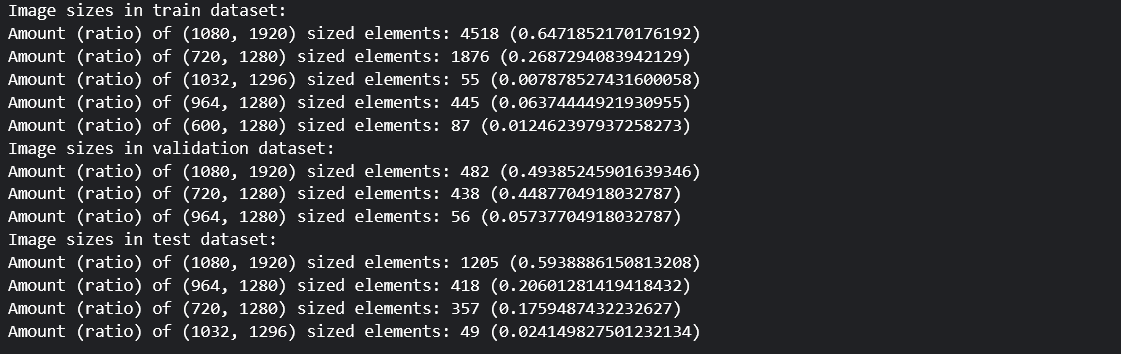

In [24]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['train'], hierarchy="high")
# train_batch_sampler_ii = SameShapeBatchSampler(train_dataset_ii, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader_ii = DataLoader(
#     train_dataset_ii, batch_sampler=train_batch_sampler_ii, num_workers=4
# )

# # Validation dataloader
# val_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['val'], hierarchy="high")
# val_batch_sampler_ii = SameShapeBatchSampler(val_dataset_ii, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader_ii = DataLoader(
#     val_dataset_ii, batch_sampler=val_batch_sampler_ii, num_workers=4
# )

# # Test dataloader
# test_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler_ii = SameShapeBatchSampler(test_dataset_ii, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader_ii = DataLoader(
#     test_dataset_ii, batch_sampler=test_batch_sampler_ii, num_workers=4
# )

## Image sizes in the part II

In [25]:
# print("Image sizes in train dataset: ")
# train_dataset_ii.image_shapes_quantity(print_flag=True)
# print("Image sizes in validation dataset: ")
# val_dataset_ii.image_shapes_quantity(print_flag=True)
# print("Image sizes in test dataset: ")
# test_dataset_ii.image_shapes_quantity(print_flag=True)

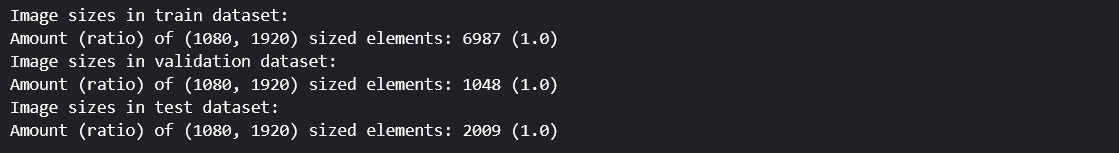

## Full dataset

In [26]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                  splits = ['train'], hierarchy="high")
# train_batch_sampler_full = SameShapeBatchSampler(train_dataset_full, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader_full = DataLoader(
#     train_dataset_full, batch_sampler=train_batch_sampler_full, num_workers=4
# )

# # Validation dataloader
# val_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                splits = ['val'], hierarchy="high")
# val_batch_sampler_full = SameShapeBatchSampler(val_dataset_full, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader_full = DataLoader(
#     val_dataset_full, batch_sampler=val_batch_sampler_full, num_workers=4
# )

# # Test dataloader
# test_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler_full = SameShapeBatchSampler(test_dataset_full, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader_full = DataLoader(
#     test_dataset_full, batch_sampler=test_batch_sampler_full, num_workers=4
# )

In [27]:
labeled_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['train'], hierarchy=CURRENT_HIERARCHY_STR)

# Outdated
# val_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['val'], hierarchy=CURRENT_HIERARCHY_STR)
# train_lab_dataset, train_unlab_dataset_i, train_unlab_dataset_ii, test_dataset  = random_split(labeled_full, [0.053242, 0.372549, 0.355947, 0.218262])

# test_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['val'], hierarchy=CURRENT_HIERARCHY_STR)
# train_lab_dataset, train_unlab_dataset_i, train_unlab_dataset_ii, val_dataset, _  = random_split(labeled_full, [0.050236, 0.187777, 0.187777, 0.100187, 0.474023])

test_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['val'], hierarchy=CURRENT_HIERARCHY_STR)
train_lab_dataset, train_unlab_dataset, val_dataset, _  = random_split(labeled_full, [0.053242, 0.372549, 0.100187, 0.474022])

# 0.2126, 0.5979, 0.1137, 0.0758

# unlabeled_part_i = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['test'], hierarchy="high")
# train_unlab_dataset = ConcatDataset([unlabeled_part_i, unlabeled_part_ii]) # 0.0005, 0.999, 0.00025, 0.00025

KeyboardInterrupt: 

In [ ]:
# Labeled training dataloader
# Supervised training
train_lab_batch_sampler_st = SameShapeBatchSampler(train_lab_dataset, BATCH_SIZE_ST,
                                            shuffle=True,
                                            drop_last=True,
                                            generator=g_train_l_st)
train_lab_loader_st = DataLoader(
    train_lab_dataset, batch_sampler=train_lab_batch_sampler_st, num_workers=4,
    worker_init_fn=seed_worker, generator=g_train_l_st
)
# Semi-supervised training
train_lab_batch_sampler_sst = SameShapeBatchSampler(train_lab_dataset, BATCH_SIZE_SST,
                                            shuffle=True,
                                            drop_last=True,
                                            generator=g_train_l_sst)
train_lab_loader_sst = DataLoader(
    train_lab_dataset, batch_sampler=train_lab_batch_sampler_sst, num_workers=4,
    worker_init_fn=seed_worker, generator=g_train_l_sst
)

# # Unlabeled training dataloader i
# train_unlab_batch_sampler_i = SameShapeBatchSampler(train_unlab_dataset_i, UNLAB_MULT * BATCH_SIZE_SST,
#                                             shuffle=True,
#                                             drop_last=True,
#                                             generator=g_train_ul_i)
# train_unlab_loader_i = DataLoader(
#     train_unlab_dataset_i, batch_sampler=train_unlab_batch_sampler_i, num_workers=4,
#     worker_init_fn=seed_worker, generator=g_train_ul_i
# )

# # Unlabeled training dataloader ii
# train_unlab_batch_sampler_ii = SameShapeBatchSampler(train_unlab_dataset_ii, UNLAB_MULT * BATCH_SIZE_SST,
#                                             shuffle=True,
#                                             drop_last=True,
#                                             generator=g_train_ul_ii)
# train_unlab_loader_ii = DataLoader(
#     train_unlab_dataset_ii, batch_sampler=train_unlab_batch_sampler_ii, num_workers=4,
#     worker_init_fn=seed_worker, generator=g_train_ul_ii
# )

# #Merged unlab training dataloader
# train_unlab_dataset = ConcatDataset([train_unlab_dataset_i, train_unlab_dataset_ii])
train_unlab_batch_sampler = SameShapeBatchSampler(train_unlab_dataset, UNLAB_MULT * BATCH_SIZE_SST,
                                            shuffle=True,
                                            drop_last=True,
                                            generator=g_train_ul_full)
train_unlab_loader = DataLoader(
    train_unlab_dataset, batch_sampler=train_unlab_batch_sampler, num_workers=4,
    worker_init_fn=seed_worker, generator=g_train_ul_full
)

# Validation dataloader
val_batch_sampler = SameShapeBatchSampler(val_dataset, BATCH_SIZE_ST,
                                          shuffle=False,
                                          drop_last=False,
                                          generator=g_val)
val_loader = DataLoader(
    val_dataset, batch_sampler=val_batch_sampler, num_workers=4,
    worker_init_fn=seed_worker, generator=g_val
)

# Test dataloader
test_batch_sampler = SameShapeBatchSampler(test_dataset, BATCH_SIZE_ST,
                                           shuffle=False,
                                           drop_last=False,
                                           generator=g_test)
test_loader = DataLoader(
    test_dataset, batch_sampler=test_batch_sampler, num_workers=4,
    worker_init_fn=seed_worker, generator=g_test
)

In [ ]:
total_samples = len(train_lab_dataset) + len(train_unlab_dataset) + len(val_dataset) + len(test_dataset) #  + len(train_unlab_dataset_i) + len(train_unlab_dataset_ii)
print(f"Quantity of samples in the current split:")
print(f"   Train labeled: {len(train_lab_dataset)} (ratio: {len(train_lab_dataset)/total_samples})")
print(f"   Train unlabeled: {len(train_unlab_dataset)} (ratio: {len(train_unlab_dataset)/total_samples})")
# print(f"   Train unlabeled i: {len(train_unlab_dataset_i)} (ratio: {len(train_unlab_dataset_i)/total_samples})")
# print(f"   Train unlabeled ii: {len(train_unlab_dataset_ii)} (ratio: {len(train_unlab_dataset_ii)/total_samples})")
print(f"   Validation: {len(val_dataset)} (ratio: {len(val_dataset)/total_samples})")
print(f"   Test: {len(test_dataset)} (ratio: {len(test_dataset)/total_samples})")

## Additional info calculation

In [ ]:
# temp_batch_size = 128
# # Shuffling is ensured by the sampler
# # train_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
# #                                  splits = ['train'], hierarchy="high")
# train_dataset_full = ConcatDataset([train_lab_dataset, train_unlab_dataset_i, train_unlab_dataset_ii])
# train_full_batch_sampler_calc = SameShapeBatchSampler(train_dataset_full, temp_batch_size,
#                                             shuffle=True,
#                                             drop_last=False,
#                                             generator=g_train_l_st)
# train_full_loader_calc = DataLoader(
#     train_dataset_full, batch_sampler=train_full_batch_sampler_calc, num_workers=4, worker_init_fn=seed_worker, generator=g_train_l_st
# )

# to_tensor_pipe = transformsv2.Compose([
#     transformsv2.ToImage(),
#     transformsv2.ToDtype(torch.float32, scale=True)
# ])
# total_len = len(train_full_loader_calc)

### Mean/std calculation

In [ ]:
# train_loader_full = DataLoader(
#     train_dataset_full,
#     batch_sampler=SameShapeBatchSampler(train_dataset_full, temp_batch_size,
#                                         shuffle=True,
#                                         drop_last=False,
#                                         generator=g_train_l_st),
#     num_workers=4, worker_init_fn=seed_worker, generator=g_train_l_st
#     )
# len(train_loader_full)

In [ ]:
# # Initialize variables to store sum and sum of squares
# mean_arr = np.zeros((total_len,3))
# std_arr = np.zeros((total_len,3))

# # Iterate over the dataset
# for batch_num, data in tqdm(enumerate(train_full_loader_calc), total=total_len):
#     images, _ = data  # We only need the images, not the masks
#     images = to_tensor_pipe(images).numpy()
#     batch_mean = np.mean(images, axis=(0,2,3))
#     batch_std1 = np.std(images, axis=(0,2,3), ddof=1)
    
#     mean_arr[batch_num, :] = batch_mean
#     std_arr[batch_num, :] = batch_std1

# DATA_MEAN = mean_arr.mean(axis=0)
# DATA_STD = std_arr.mean(axis=0)
# np.save("channel_mean_data_ii_1_9lab.npy", DATA_MEAN)
# np.save("channel_std_data_ii_1_9lab.npy", DATA_STD)

### Class weights calculation

In [ ]:
# train_loader_full = DataLoader(
#     train_dataset_full, batch_size=temp_batch_size,
#     sampler=SameShapeBatchSampler(train_dataset_full, temp_batch_size, g_train),
#     drop_last=False, num_workers=4, worker_init_fn=seed_worker, generator=g_train
#     )
# len(train_loader_full)

In [ ]:
# # Convert to numpy array
# total_class_ratios = np.zeros(CURRENT_NUM_CLASSES)

# # Iterate over the dataset
# for batch_num, data in tqdm(enumerate(train_full_loader_calc), total=total_len):
#     _, masks = data  # We only need the masks, not the images
#     masks_np = masks.detach().cpu().numpy()
#     class_counts = [(masks_np == cls).sum(axis=(1, 2)) for cls in range(CURRENT_NUM_CLASSES)]
#     class_ratios = np.array(class_counts) / (masks_np != CURRENT_NUM_CLASSES).sum(axis=(1, 2)) # unlabeled pixels not taken into account
#     # Calculate the mean ratio for each class across all masks
#     mean_ratios = class_ratios.mean(axis=1)
#     total_class_ratios += mean_ratios
    
# class_weights_ii = total_class_ratios / total_len

In [ ]:
# np.save("class_ratio_dataset_ii.npy", class_weights_ii)

In [ ]:
# np.save("class_weights_dataset_ii.npy",\
#         np.round((1/class_weights_ii) / (np.min(1/class_weights_ii)), 5))

### File reading time calculation

In [ ]:
# from torchvision.io.image import decode_jpeg, read_file
# from torchvision.io import read_image
# start = time.time()
# img = PIL.Image.open("/kaggle/input/indian-driving-dataset/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# tensor = read_image("/kaggle/input/indian-driving-dataset/idd_seg_part_I_leftImg8bit/train/0/005506_leftImg8bit.png")
# data = read_file("/kaggle/input/indian-driving-dataset/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# tensor = decode_jpeg(data, device="cpu")
# img = np.array(img)
# img = torchvision.transforms.functional.pil_to_tensor(img)
# array = np.load("/kaggle/input/indian-driving-dataset/idd_seg_part_I_gtFine/train/0/005506_gtFine_polygons.npz")['masks']
# end = time.time()
# end - start

# Augmentation visualisations

In [ ]:
# model_b1 = model_b1.to(DEVICE)
# test_img, test_real_mask = train_lab_dataset[2]
# apply_model_and_show_results(
#     model = model_b1,
#     image = test_img,
#     new_height = NEW_HEIGHT,
#     new_width = NEW_WIDTH,
#     real_mask = test_real_mask
# )

In [ ]:
# apply_model_and_show_results(
#     model = model_b1,
#     image = test_img,
#     new_height = NEW_HEIGHT,
#     new_width = NEW_WIDTH,
#     real_mask = test_real_mask,
#     transform = strong_transform_st
# )

In [ ]:
# apply_model_and_show_results(
#     model = model_b1,
#     image = test_img,
#     new_height = NEW_HEIGHT,
#     new_width = NEW_WIDTH,
#     real_mask = test_real_mask,
#     transform = transformsv2.Compose([weak_transform_i, weak_transform_ii])
# )

In [ ]:
# apply_model_and_show_results(
#     model = model_b1,
#     image = test_img,
#     new_height = CENTER_CROP_HEIGHT,
#     new_width = CENTER_CROP_WIDTH,
#     real_mask = test_real_mask,
#     transform = inference_transform
# )

# Lightning Modules
# Supervised training

In [ ]:
# define the LightningModule
class LitSegSupervised(L.LightningModule):
    def __init__(
        self,
        seg_model,
        train_loader,
        val_dataset,
        test_dataset,
        level_mapping,
        strong_transform,
        inference_transform,
        output_epoch=1,
        num_warmup_epochs=2,
        row_num=5,
        criterion = nn.CrossEntropyLoss,
        cmap=CURRENT_CMAP,
        norm=CURRENT_NORM,
        std_img=STD_TRN,
        mean_img=MEAN_TRN,
        weights=CLASS_WEIGHTS
    ):
        super().__init__()
        self.seg_model = seg_model
        self.num_classes = seg_model.head.output_ops[0].op_list[1].conv.out_channels
        self.ignored_index = len(level_mapping) - 1
        
        if weights is not None:
            weights = weights.float()
        
        self.criterion = criterion(weight=weights, ignore_index=self.ignored_index)
        self.row_num = row_num
        self.train_loader_len = len(train_loader)
        self.output_epoch = output_epoch
        self.num_warmup_epochs = num_warmup_epochs
        self.strong_aug = strong_transform
        self.inference_transform = inference_transform
        self.std_img = std_img
        self.mean_img = mean_img

#         self.mean_iou = CustomMeanIoU(num_classes=self.num_classes+1, include_background=False)
#         self.dice = CustomGeneralizedDiceScore(num_classes=self.num_classes+1, include_background=False)

        # 0 - train, 1 - validation, 2 - test
        self.mean_iou = nn.ModuleList([
            MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)\
            for _ in range(3)
        ])
        self.dice = nn.ModuleList([
            Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.precision = nn.ModuleList([
            MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.recall = nn.ModuleList([
            MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.accuracy = nn.ModuleList([
            MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])

        
        def get_control_data(dataset, num_items, img_shape=(3, 1080, 1920)):
            image_list, mask_list = [], []
            count = 0
            # Iterate over the dataset
            for image, mask in dataset:
                # Stop after num_items iterations
                if count == num_items:
                    break
                elif image.shape != img_shape:
                    continue
                # Add the tensors to the lists
                image_list.append(image)
                mask_list.append(mask)
                count += 1

            # Convert the lists of tensors to a single tensor
            images = torch.stack(image_list)
            masks = Mask(torch.stack(mask_list))
            return images, masks
        
        self.val_control_images, self.val_control_masks = get_control_data(val_dataset, row_num)
        self.test_control_images, self.test_control_masks = get_control_data(test_dataset, row_num)

        self.cmap = cmap
        self.norm = norm


    def forward(self, x):
        return self.seg_model(x)


    def training_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.strong_aug(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[0](pred_labels, y)
        self.precision[0](pred_labels, y)
        self.recall[0](pred_labels, y)
        self.accuracy[0](pred_labels, y)
        self.dice[0](pred_labels, y)

        self.log_dict({
            'train_loss': loss, 
            'train_mIoU': self.mean_iou[0],
            'train_precision': self.precision[0],
            'train_recall': self.recall[0],
            'train_accuracy': self.accuracy[0],
            'train_dice_score': self.dice[0],
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True)

        return loss


    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[1](pred_labels, y)
        self.precision[1](pred_labels, y)
        self.recall[1](pred_labels, y)
        self.accuracy[1](pred_labels, y)
        self.dice[1](pred_labels, y)

        self.log_dict({
            'val_loss': loss, 
            'val_mIoU': self.mean_iou[1],
            'val_precision': self.precision[1],
            'val_recall': self.recall[1],
            'val_accuracy': self.accuracy[1],
            'val_dice_score': self.dice[1],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)


    def on_validation_epoch_end(self):
        if self.current_epoch % self.output_epoch == 0:
            x, y = self.inference_transform(
                self.val_control_images.to(self.device),
                self.val_control_masks.to(self.device)
            )
            # Get the model predictions for the control images
            y = y.long()
            logits = self(x)
            if logits.shape[2:] != y.shape[1:]:
                logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

            # Convert the tensors to numpy arrays
            control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
            control_masks_np = y.detach().cpu().numpy()

            # Create a figure with self.row_num rows and 3 columns
            fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

            # Loop over the images, predicted masks, and actual masks
            for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
                # Display the image in the first column
                axs[i, 0].imshow(img, interpolation='none')
                axs[i, 0].axis('off')

                # Overlay the predicted mask on the image and display it in the second column
                axs[i, 1].imshow(img, cmap='gray', interpolation='none')
                axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 1].axis('off')

                # Overlay the actual mask on the image and display it in the third column
                axs[i, 2].imshow(img, cmap='gray', interpolation='none')
                axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 2].axis('off')

            # Display the figure
            plt.show()
        

    def test_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[2](pred_labels, y)
        self.precision[2](pred_labels, y)
        self.recall[2](pred_labels, y)
        self.accuracy[2](pred_labels, y)
        self.dice[2](pred_labels, y)
        
        self.log_dict({
            'test_loss': loss, 
            'test_mIoU': self.mean_iou[2],
            'test_precision': self.precision[2],
            'test_recall': self.recall[2],
            'test_accuracy': self.accuracy[2],
            'test_dice_score': self.dice[2],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)


    def on_test_epoch_end(self):
        x, y = self.inference_transform(
            self.test_control_images.to(self.device),
            self.test_control_masks.to(self.device)
        )
        # Get the model predictions for the control images
        y = y.long()
        logits = self(x)
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

        # Convert the tensors to numpy arrays
        control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
        control_masks_np = y.detach().cpu().numpy()

        # Create a figure with self.row_num rows and 3 columns
        fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

        # Loop over the images, predicted masks, and actual masks
        for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
            # Display the image in the first column
            axs[i, 0].imshow(img, interpolation='none')
            axs[i, 0].axis('off')

            # Overlay the predicted mask on the image and display it in the second column
            axs[i, 1].imshow(img, cmap='gray', interpolation='none')
            axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 1].axis('off')

            # Overlay the actual mask on the image and display it in the third column
            axs[i, 2].imshow(img, cmap='gray', interpolation='none')
            axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 2].axis('off')

        # Display the figure
        plt.show()


    def configure_optimizers(self):
        params = list(self.seg_model.named_parameters())

        def is_backbone(n): return 'backbone' in n

        grouped_parameters = [
            {"params": [p for n, p in params if is_backbone(n)], 'lr': 1e-4}, # 7e-4
            {"params": [p for n, p in params if not is_backbone(n)], 'lr': 1e-3}, # 7e-3
        ]

        optimizer = torch.optim.AdamW(
            grouped_parameters, weight_decay=1e-4
        )
        
        num_warmup_steps = self.num_warmup_epochs * self.train_loader_len
        num_training_steps = self.trainer.max_epochs * self.train_loader_len
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps)

        return {"optimizer": optimizer, "lr_scheduler": scheduler}

## Training

In [ ]:
# lit_model_b1 = LitSegSupervised(model_b1, train_lab_loader_st, val_dataset, test_dataset,
#     CURRENT_LEVEL_MAPPING, strong_transform_st, inference_transform, output_epoch=8, num_warmup_epochs=8,
#     weights=None)

# # L.seed_everything(RAND_CONST, workers=True) # reproducibility

# # Initialize a model checkpoint callback
# checkpoint_callback = ModelCheckpoint(
#     monitor='val_mIoU',
#     dirpath='/kaggle/working/checkpoints',
#     filename='EViT_sup_pretr16_80ep_warmup8_trcrop_eq_tstcrop_416X632_data2_1_8labdata-{epoch:02d}-{val_mIoU:.5f}',
#     save_last=True,
#     save_top_k=1,
#     mode='max',
# )

# # Define the early stopping callback when mIoU has stopped improving
# early_stop_callback = EarlyStopping(
#     monitor="val_mIoU",
#     min_delta=0.00,
#     patience=10,
#     verbose=False,
#     mode="max"
# )

# trainer = L.Trainer(
#     max_epochs=80,
#     enable_checkpointing=True,
#     callbacks=[checkpoint_callback, early_stop_callback],
#     logger=TensorBoardLogger('lightning_logs', name='EViT_sup_pretr16_80ep_warmup8_trcrop_eq_tstcrop_416X632_data2_1_8labdata'),
# #     deterministic='warn',
# #     limit_train_batches=2,
# #     limit_val_batches=2
# )
# trainer.fit(lit_model_b1, train_lab_loader_st, val_loader)

In [ ]:
# lit_model_b1 = LitSegSupervised.load_from_checkpoint(
#     "/kaggle/working/checkpoints/EViT_sup_pretr16_80ep_warmup8_trcrop_eq_tstcrop_416X632_data2_1_8labdata-epoch=79-val_mIoU=0.70970.ckpt",
#     seg_model=model_b1,
#     train_loader=train_lab_loader_st,
#     val_dataset=val_dataset,
#     test_dataset=test_dataset,
#     level_mapping=CURRENT_LEVEL_MAPPING,
#     strong_transform=strong_transform_st,
#     inference_transform=inference_transform,
#     output_epoch=10,
#     num_warmup_epochs=8,
#     weights=None)

In [ ]:
# !dir /kaggle/working/checkpoints

In [ ]:
# torch.save(lit_model_b1.seg_model, "EfficientVit_supv16_416_832_80_ep_samecrop_data2_lab1_8_7class_70_102_tstmIoU.pth")

In [ ]:
# trainer.test(lit_model_b1, test_loader, ckpt_path="/kaggle/working/checkpoints/EViT_sup_pretr16_80ep_warmup8_trcrop_eq_tstcrop_416X632_data2_1_8labdata-epoch=79-val_mIoU=0.70970.ckpt")

In [ ]:
# !zip -r /kaggle/working/lightning_logs.zip /kaggle/working/efficientvit/lightning_logs

In [ ]:
# !zip -r /kaggle/working/checkpoints.zip /kaggle/working/checkpoints

# Semi-supervised finetune

In [ ]:
CLASS_CONF_DICT = {}
# define the LightningModule
class LitSegSemiSupervised(LitSegSupervised):
    def __init__(
        self,
        seg_model,
        train_lab_loader,
#         train_unlab_loader_i,
#         train_unlab_loader_ii,
        val_dataset,
        test_dataset,
        level_mapping,
        strong_transform_st,
        pre_strong_transform_sst,
        post_strong_transform_sst,
        weak_transform_i,
        weak_transform_ii,
        inference_transform,
        confidence_threshold=0.95,
        mu=5,
        mu_strategy="const",
        output_epoch=1,
        num_warmup_epochs=2,
        row_num=5,
        criterion = nn.CrossEntropyLoss,
        cmap=CURRENT_CMAP,
        norm=CURRENT_NORM,
        std_img=STD_TRN,
        mean_img=MEAN_TRN,
        decay_val=DECAY_VAL,
        ema_strategy="const",
        weights=CLASS_WEIGHTS,
        weighting="ordinary",
        cut_mix_mode="adapted",
        class_mix_mode="adapted"
    ):
        super().__init__(
            seg_model,
            train_lab_loader,
            val_dataset,
            test_dataset,
            level_mapping,
            strong_transform=strong_transform_st,
            inference_transform=inference_transform,
            output_epoch=output_epoch,
            num_warmup_epochs=num_warmup_epochs,
            row_num=row_num,
            criterion=criterion,
            cmap=cmap,
            norm=norm,
            std_img=std_img,
            mean_img=mean_img,
            weights=weights
        )
        self.seg_model = self.seg_model

#         self.teacher_even = ExponentialMovingAverage(self.seg_model.parameters(), decay=decay_val)
#         self.teacher_odd = ExponentialMovingAverage(self.seg_model.parameters(), decay=decay_val)
        self.teacher_even = deepcopy(self.seg_model)
        self.teacher_odd = deepcopy(self.seg_model)
#         set_sub_mode(self.teacher_even, False)
#         set_sub_mode(self.teacher_odd, False)

        if weighting!="ordinary" and weighting!="laplace":
            raise Exception(f"Error: unsupported weighting: {weighting}")
        else:
            self.weighting = weighting

        if cut_mix_mode!="adapted" and cut_mix_mode!="ordinary":
            raise Exception(f"Unknown cut_mix_mode {cut_mix_mode}")
        else:
            self.cut_mix_mode = cut_mix_mode
        if class_mix_mode!="adapted" and class_mix_mode!="max" and class_mix_mode!="ordinary":
            raise Exception(f"Unknown class_mix_mode {class_mix_mode}")
        else:
            self.class_mix_mode = class_mix_mode
        self.pre_strong_aug_sst = pre_strong_transform_sst
        self.post_strong_aug_sst = post_strong_transform_sst
        self.weak_aug_i = weak_transform_i
        self.weak_aug_ii = weak_transform_ii
        self.thr = confidence_threshold
        self.mu = mu
        self.alpha_max = decay_val
        self.current_best_model_idx = None
        
        if mu_strategy=="const":
            self.mu_func = lambda self, batch_idx: self.mu
        elif mu_strategy=="rampup":
            self.mu_func = lambda self, batch_idx: (self.current_epoch * self.trainer.num_training_batches + batch_idx) / (self.trainer.num_training_batches * self.trainer.max_epochs) * self.mu
        else:
            raise Exception(f"Unknown mu strategy: {mu_strategy}")

        if ema_strategy=="dynamical":
            self.decay_func = lambda self, batch_idx: np.minimum(batch_idx / (batch_idx + 1), self.alpha_max) # stop increasing after batch 100
        elif ema_strategy=="rampup":
            self.decay_func = lambda self, batch_idx: (self.current_epoch * self.trainer.num_training_batches + batch_idx + 1) / (self.trainer.num_training_batches * self.trainer.max_epochs) * self.alpha_max
        elif ema_strategy=="lindecline":
            self.decay_func = lambda self, batch_idx: np.maximum(1 -  (self.current_epoch * self.trainer.num_training_batches + batch_idx + 1) / (self.trainer.num_training_batches * self.trainer.max_epochs) * (1 - self.alpha_max), self.alpha_max)
        elif ema_strategy=="const":
            self.decay_func = lambda self, batch_idx: self.alpha_max
        else:
            raise Exception(f"Unknown ema alpha decay strategy: {ema_strategy}")

        if weights is not None:
            weights = weights.float()
        
        self.criterion_ul = criterion(reduction='none', weight=weights, ignore_index=self.ignored_index)
        self.mean_iou_ul = MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.dice_ul = Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.precision_ul = MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.recall_ul = MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.accuracy_ul = MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)

        # 0 - teacher_even valid, 1 - teacher_odd valid, 2 - teacher_even test, 3 - teacher_odd test
        self.mean_iou_teach = nn.ModuleList([
            MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)\
            for _ in range(4)
        ])
        self.dice_teach = nn.ModuleList([
            Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.precision_teach = nn.ModuleList([
            MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.recall_teach = nn.ModuleList([
            MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.accuracy_teach = nn.ModuleList([
            MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        
        self.train_lab_loader = train_lab_loader
#         self.train_unlab_loader_i = train_unlab_loader_i
#         self.train_unlab_loader_ii = train_unlab_loader_ii
        self.even_epoch_flag = False

    def on_train_epoch_start(self):
#         self.confidence_statistics = []
#         self.time_stats = [[],[],[],[],[],[],[],[],[]]
        if self.current_epoch % 2 == 0:
            self.current_teacher = self.teacher_even
            self.current_main_aug = self.cut_mix
            self.beta_dist = torch.distributions.beta.Beta(torch.tensor([4.0]).to(self.device), torch.tensor([4.0]).to(self.device))
        else:
            self.current_teacher = self.teacher_odd
            self.current_main_aug = self.class_mix
            
    
#     def train_dataloader(self):
#         if self.current_epoch % 2 == 0:
#             iterables = {"lab": self.train_lab_loader, "unlab": self.train_unlab_loader_i}
#             return CombinedLoader(iterables, mode="min_size")
#         else:
#             iterables = {"lab": self.train_lab_loader, "unlab": self.train_unlab_loader_ii}
#             return CombinedLoader(iterables, mode="min_size")


    def training_step(self, batch, batch_idx):
        lab_batch, unlab_batch = batch['lab'], batch['unlab']
    
        ##### Supervised part START #####
        x_lab, y_lab = lab_batch
        lab_batch_size = x_lab.shape[0]
        with torch.no_grad():
            y_lab = Mask(y_lab)
            x_lab, y_lab = self.strong_aug(x_lab, y_lab)
            y_lab = y_lab.long()
        logits_lab = self(x_lab)
        # Upsample logits if necessary
        if logits_lab.shape[2:] != y_lab.shape[1:]:
            logits_lab = F.interpolate(logits_lab, size=y_lab.shape[1:], mode='bicubic', align_corners=False)
        labeled_loss = self.criterion(logits_lab, y_lab)
        pred_labels_lab = logits_lab.argmax(dim=1)
        ##### Supervised part END #####
    
        ##### Unsupervised part START #####
        x_unlab, _ = unlab_batch
        unlab_batch_size = x_unlab.shape[0]
        with torch.no_grad():
            x_unlab = self.weak_aug_i(x_unlab)
            x_weak = self.weak_aug_ii(x_unlab)

            self.current_teacher.eval()
            teacher_logits = self.current_teacher(x_weak)
            class_num = teacher_logits.shape[1]

            if teacher_logits.shape[2:] != x_weak.shape[2:]:
                teacher_logits = F.interpolate(teacher_logits, size=x_weak.shape[2:], mode='bicubic', align_corners=False)

            y_unlab = torch.softmax(teacher_logits, dim=1) # predicted teacher probabilities
            pixel_conf_init, pseudo_labels_init = torch.max(y_unlab, dim=1)
            x_unlab = CENTER_CROP_AUG(x_unlab)
            x_unlab, pseudo_labels, pixel_conf = self.pre_strong_aug_sst(x_unlab, Mask(pseudo_labels_init), Mask(pixel_conf_init)) # y_unlab is N x C x H x W
            x_unlab_aug, y_unlab_aug, pixel_conf = self.current_main_aug(x_unlab, pseudo_labels, pixel_conf, unlab_batch_size)
            x_unlab_aug, y_unlab_aug, pixel_conf = self.post_strong_aug_sst(x_unlab_aug, Mask(y_unlab_aug), Mask(pixel_conf))

            if self.weighting == "ordinary":
                pixel_conf = (torch.sum(
                    torch.ge(pixel_conf, self.thr).long(),
                    dim=(1,2)
                ) / torch.numel(y_unlab_aug[0])).unsqueeze(1)
                mean_ratio_of_confid_pix = torch.mean(pixel_conf).item()
            else:
                pixel_conf, conf_thresh = LitSegSemiSupervised.calculate_pixel_weights(pixel_conf)
        
#         set_sub_mode(self.seg_model, False)
        logits_unlab = self(x_unlab_aug)
        # Upsample logits if necessary
        if logits_unlab.shape[2:] != y_unlab_aug.shape[1:]:
            logits_unlab = F.interpolate(logits_unlab, size=y_unlab_aug.shape[1:], mode='bicubic', align_corners=False)
        unlabeled_loss = self.criterion_ul(
            logits_unlab,
            y_unlab_aug
        )

        unlabeled_loss = torch.mean(unlabeled_loss * pixel_conf)
        pred_labels_unlab = logits_unlab.argmax(dim=1)
        ##### Unsupervised part END #####

#         ##### Unsupervised part ensemble START #####
#         set_sub_mode(self.seg_model, True)
#         logits_unlab_ensemble = self(x_weak)
        
#         if self.weighting == "ordinary":
#             pixel_conf = (torch.sum(
#                 torch.ge(pixel_conf_init, self.thr).long(),
#                 dim=(1,2)
#             ) / torch.numel(y_unlab[0])).unsqueeze(1)
#             mean_ratio_of_confid_pix = torch.mean(pixel_conf).item()
#         else:
#             pixel_conf, _ = LitSegSemiSupervised.calculate_pixel_weights(pixel_conf_init)

#         # Upsample logits if necessary
#         if logits_unlab_ensemble.shape[2:] != pseudo_labels_init.shape[1:]:
#             logits_unlab_ensemble = F.interpolate(logits_unlab_ensemble, size=pseudo_labels_init.shape[1:], mode='bicubic', align_corners=False)
#         unlabeled_loss_ensemble = self.criterion_ul(
#             logits_unlab_ensemble,
#             pseudo_labels_init
#         )

#         unlabeled_loss_ensemble = torch.mean(unlabeled_loss_ensemble * pixel_conf)
#         ##### Unsupervised part ensemble END #####
        
        total_loss = labeled_loss + self.get_mu(batch_idx) * unlabeled_loss

        self.mean_iou[0](pred_labels_lab, y_lab)
        self.precision[0](pred_labels_lab, y_lab)
        self.recall[0](pred_labels_lab, y_lab)
        self.accuracy[0](pred_labels_lab, y_lab)
        self.dice[0](pred_labels_lab, y_lab)
        
        self.mean_iou_ul(pred_labels_unlab, y_unlab_aug)
        self.precision_ul(pred_labels_unlab, y_unlab_aug)
        self.recall_ul(pred_labels_unlab, y_unlab_aug)
        self.accuracy_ul(pred_labels_unlab, y_unlab_aug)
        self.dice_ul(pred_labels_unlab, y_unlab_aug)

        # Logging several times, since labeled and unlabeled batch sizes are different
        self.log_dict({
            'train_total_loss': total_loss
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True)
        self.log_dict({
            'train_labeled_loss': labeled_loss,
            'train_mIoU_lab': self.mean_iou[0],
            'train_precision_lab': self.precision[0],
            'train_recall_lab': self.recall[0],
            'train_accuracy_lab': self.accuracy[0],
            'train_dice_score_lab': self.dice[0]
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=lab_batch_size)
        self.log_dict({
            'train_unlabeled_loss': unlabeled_loss,
            'quant_of_img_passed_thr' if self.weighting == "ordinary" else "20th_percentile":\
                mean_ratio_of_confid_pix if self.weighting == "ordinary" else conf_thresh,
            'train_mIoU_unlab': self.mean_iou_ul,
            'train_precision_unlab': self.precision_ul,
            'train_recall_unlab': self.recall_ul,
            'train_accuracy_unlab': self.accuracy_ul,
            'train_dice_score_unlab': self.dice_ul                                                #!!!!!!!!!!
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=unlab_batch_size) # replaced unlab_batch_size

#         self.confidence_statistics.append(pixel_conf.detach().cpu().numpy())
#         with open('conf_stat.pkl', 'wb') as file:
#             pickle.dump(self.confidence_statistics, file)
#         entire_stop = time.time()
#         print(f"Entire train time: {entire_stop-entire_start}")

        self.current_batch_idx = batch_idx
        return total_loss


#     def on_train_epoch_end(self):
#         self.confidence_statistics = np.array(self.confidence_statistics)
#         np.save("conf_stat.npy", self.confidence_statistics)


    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits_student = self(x)
        # Upsample logits if necessary
        if logits_student.shape[2:] != y.shape[1:]:
            logits_student = F.interpolate(logits_student, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits_student, y)
        pred_labels = logits_student.argmax(dim=1)

        self.mean_iou[1](pred_labels, y)
        self.precision[1](pred_labels, y)
        self.recall[1](pred_labels, y)
        self.accuracy[1](pred_labels, y)
        self.dice[1](pred_labels, y)

        self.log_dict({
            'val_loss': loss, 
            'val_mIoU': self.mean_iou[1],
            'val_precision': self.precision[1],
            'val_recall': self.recall[1],
            'val_accuracy': self.accuracy[1],
            'val_dice_score': self.dice[1],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

        del logits_student, loss, pred_labels
        torch.cuda.empty_cache()

        for idx, teacher, name in zip(range(2),
                                      (self.teacher_even, self.teacher_odd),
                                      ("teach_even", "teach_odd")):

            with torch.no_grad():
                teacher.eval()
                teacher_logits = teacher(x)

            # Upsample logits if necessary
            if teacher_logits.shape[2:] != y.shape[1:]:
                teacher_logits = F.interpolate(teacher_logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            loss = self.criterion(teacher_logits, y)
            pred_labels = teacher_logits.argmax(dim=1)

            self.mean_iou_teach[idx](pred_labels, y)
            self.precision_teach[idx](pred_labels, y)
            self.recall_teach[idx](pred_labels, y)
            self.accuracy_teach[idx](pred_labels, y)
            self.dice_teach[idx](pred_labels, y)

            self.log_dict({
                f'val_loss_{name}': loss, 
                f'val_mIoU_{name}': self.mean_iou_teach[idx],
                f'val_precision_{name}': self.precision_teach[idx],
                f'val_recall_{name}': self.recall_teach[idx],
                f'val_accuracy_{name}': self.accuracy_teach[idx],
                f'val_dice_score_{name}': self.dice_teach[idx],
                }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

            del teacher_logits, loss, pred_labels
            torch.cuda.empty_cache()

   
    def on_validation_epoch_end(self):
        # Compute the maximum mIoU
        mIoU_models_arr = torch.tensor([
            self.mean_iou[1].compute(), # student val mIoU
            self.mean_iou_teach[0].compute(), # teacher_cutmix val mIoU
            self.mean_iou_teach[1].compute() # teacher_classmix val mIoU
        ])
        current_best_model_idx = torch.argmax(mIoU_models_arr)
        current_best_mIoU = mIoU_models_arr[current_best_model_idx]
        # Log the custom metric
        self.log('max_val_mIoU', current_best_mIoU)
        if current_best_model_idx == 0:
            current_best_model = self
        elif current_best_model_idx == 1:
            current_best_model = self.teacher_even
        elif current_best_model_idx == 2:
            current_best_model = self.teacher_odd
        else:
            raise Exception(f"Unknown best model with idx: {current_best_model_idx}")
        
        if self.current_epoch % self.output_epoch == 0:
            x, y = self.inference_transform(
                self.val_control_images.to(self.device),
                self.val_control_masks.to(self.device)
            )
            # Get the model predictions for the control images
            y = y.long()
            logits = current_best_model(x)
            if logits.shape[2:] != y.shape[1:]:
                logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

            # Convert the tensors to numpy arrays
            control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
            control_masks_np = y.detach().cpu().numpy()

            # Create a figure with self.row_num rows and 3 columns
            fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

            # Loop over the images, predicted masks, and actual masks
            for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
                # Display the image in the first column
                axs[i, 0].imshow(img, interpolation='none')
                axs[i, 0].axis('off')

                # Overlay the predicted mask on the image and display it in the second column
                axs[i, 1].imshow(img, cmap='gray', interpolation='none')
                axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 1].axis('off')

                # Overlay the actual mask on the image and display it in the third column
                axs[i, 2].imshow(img, cmap='gray', interpolation='none')
                axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 2].axis('off')

            # Display the figure
            plt.show()
            
            
    def test_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[2](pred_labels, y)
        self.precision[2](pred_labels, y)
        self.recall[2](pred_labels, y)
        self.accuracy[2](pred_labels, y)
        self.dice[2](pred_labels, y)
        
        self.log_dict({
            'test_loss': loss, 
            'test_mIoU': self.mean_iou[2],
            'test_precision': self.precision[2],
            'test_recall': self.recall[2],
            'test_accuracy': self.accuracy[2],
            'test_dice_score': self.dice[2],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)
        
        del logits, loss, pred_labels
        torch.cuda.empty_cache()
        
        for idx, teacher, name in zip(range(2, 4),
                              (self.teacher_even, self.teacher_odd),
                              ("teach_even", "teach_odd")):

            with torch.no_grad():
                teacher.eval()
                teacher_logits = teacher(x)

            # Upsample logits if necessary
            if teacher_logits.shape[2:] != y.shape[1:]:
                teacher_logits = F.interpolate(teacher_logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            loss = self.criterion(teacher_logits, y)
            pred_labels = teacher_logits.argmax(dim=1)

            self.mean_iou_teach[idx](pred_labels, y)
            self.precision_teach[idx](pred_labels, y)
            self.recall_teach[idx](pred_labels, y)
            self.accuracy_teach[idx](pred_labels, y)
            self.dice_teach[idx](pred_labels, y)

            self.log_dict({
                f'test_loss_{name}': loss, 
                f'test_mIoU_{name}': self.mean_iou_teach[idx],
                f'test_precision_{name}': self.precision_teach[idx],
                f'test_recall_{name}': self.recall_teach[idx],
                f'test_accuracy_{name}': self.accuracy_teach[idx],
                f'test_dice_score_{name}': self.dice_teach[idx],
                }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

            del teacher_logits, loss, pred_labels
            torch.cuda.empty_cache()


    def on_test_epoch_end(self):
        # Compute the maximum mIoU
        mIoU_models_arr = torch.tensor([
            self.mean_iou[2].compute(), # student test mIoU
            self.mean_iou_teach[2].compute(), # teacher_cutmix test mIoU
            self.mean_iou_teach[3].compute() # teacher_classmix test mIoU
        ])
        current_best_model_idx = torch.argmax(mIoU_models_arr)
        current_best_mIoU = mIoU_models_arr[current_best_model_idx]
        # Log the custom metric
        self.log('max_test_mIoU', current_best_mIoU)
        if current_best_model_idx == 0:
            current_best_model = self
        elif current_best_model_idx == 1:
            current_best_model = self.teacher_even
        elif current_best_model_idx == 2:
            current_best_model = self.teacher_odd
        else:
            raise Exception(f"Unknown best model with idx: {current_best_model_idx}")

        x, y = self.inference_transform(
            self.test_control_images.to(self.device),
            self.test_control_masks.to(self.device)
        )
        # Get the model predictions for the control images
        y = y.long()
        logits = current_best_model(x)
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

        # Convert the tensors to numpy arrays
        control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
        control_masks_np = y.detach().cpu().numpy()

        # Create a figure with self.row_num rows and 3 columns
        fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

        # Loop over the images, predicted masks, and actual masks
        for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
            # Display the image in the first column
            axs[i, 0].imshow(img, interpolation='none')
            axs[i, 0].axis('off')

            # Overlay the predicted mask on the image and display it in the second column
            axs[i, 1].imshow(img, cmap='gray', interpolation='none')
            axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 1].axis('off')

            # Overlay the actual mask on the image and display it in the third column
            axs[i, 2].imshow(img, cmap='gray', interpolation='none')
            axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 2].axis('off')

        # Display the figure
        plt.show()


    def on_before_zero_grad(self, *args, **kwargs):
        LitSegSemiSupervised.update_ema_parameters(
            self.current_teacher, self.seg_model, self.get_decay(self.current_batch_idx)
        )


    def configure_optimizers(self):
        params = list(self.seg_model.named_parameters())

        def is_backbone(n): return 'backbone' in n

        grouped_parameters = [
            {"params": [p for n, p in params if is_backbone(n)], 'lr': 5e-4},#5e-4
            {"params": [p for n, p in params if not is_backbone(n)], 'lr': 2e-3},#2e-3
        ]

        optimizer = torch.optim.AdamW(
            grouped_parameters, weight_decay=1e-4
        )
        
        num_warmup_steps = self.num_warmup_epochs * self.train_loader_len
        num_training_steps = self.trainer.max_epochs * self.train_loader_len
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps)

        return {"optimizer": optimizer, "lr_scheduler": scheduler}


    def cut_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
        x_unlab_aug, pseudo_labels_aug = x_unlab.clone(), pseudo_labels.clone()
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        # Line of the code below won't work correctly together with affine transformations
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx]
        
        if self.cut_mix_mode=="adapted":
            mean_conf = torch.mean(pixel_conf, dim=(1,2)).detach() # mean confidence for each image in a batch
            mean_conf_shuff = mean_conf[shuff_idx]
            neg_sqrt_lambda_arr = torch.sqrt(1 - (mean_conf / (mean_conf + mean_conf_shuff)))
        else:
            neg_sqrt_lambda_arr = torch.sqrt(1 - self.beta_dist.sample())

        r_y = torch.randint(
            low=0, high=x_unlab.shape[2], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_x = torch.randint(
            low=0, high=x_unlab.shape[3], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_h = (x_unlab.shape[2] * neg_sqrt_lambda_arr).detach()
        r_w = (x_unlab.shape[3] * neg_sqrt_lambda_arr).detach()

        x_left = torch.max(r_x - r_w/2, torch.tensor(0).to(self.device).detach()).round().int()
        x_right = torch.min(r_x + r_w/2, torch.tensor(x_unlab.shape[3]).to(self.device).detach()).round().int()
        y_up = torch.max(r_y - r_h/2, torch.tensor(0).to(self.device).detach()).round().int()
        y_down = torch.min(r_y + r_h/2, torch.tensor(x_unlab.shape[2]).to(self.device).detach()).round().int()

        for idx in range(unlab_batch_size):
#             x_unlab = x_unlab.clone() # prevent in-place error in backward gradient flow
            x_unlab_aug[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                x_unlab_shuff[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
#             pseudo_labels = pseudo_labels.clone() # prevent in-place error in backward gradient flow
            pseudo_labels_aug[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pseudo_labels_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
            pixel_conf[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pixel_conf_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
        # !!!
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels_aug[0])
        
        #       conf[idx] = lambd * conf[idx] + (1 - lambd) * conf_shuff[idx]

        del x_unlab, pseudo_labels, x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff,\
            shuff_idx, neg_sqrt_lambda_arr, r_y, r_x, r_h, r_w, x_left, x_right, y_up, y_down
            #pixel_conf !!!
        if self.cut_mix_mode=="adapted":
            del mean_conf_shuff, mean_conf
        torch.cuda.empty_cache()

        return x_unlab_aug, pseudo_labels_aug, pixel_conf #sample_weights


    def class_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
        def select_n_unique_classes(dist, n, present_classes):
            selected_classes = torch.zeros(n).to(self.device).long()
            dist = dist.clone()
            present_classes = present_classes.clone()
            for i in range(n):
                # Create the cumulative distribution
                p = dist.cumsum(0)
                # Find the index corresponding to the random value
                idx = torch.searchsorted(p, torch.rand(1).to(self.device))
                # Add the index to the list of selected indices
                selected_classes[i] = present_classes[idx].item()
                mask = torch.ones(present_classes.size(0), dtype=torch.bool).to(self.device).detach()
                mask[idx] = False
                present_classes = present_classes[mask]
                dist = dist[mask]
                # Re-normalize the probabilities
                dist = dist / dist.sum()
            return selected_classes
        
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx]
#         mask_arr = torch.zeros_like(pseudo_labels).detach().to(self.device)

        for idx in range(unlab_batch_size):
            img_classes = torch.unique(pseudo_labels_shuff[idx]).detach()
            if self.class_mix_mode=="adapted":
                img_classes, _ = img_classes.sort()
#             img_classes = img_classes[~torch.isin(img_classes, ABUNDANT_CLASSES.to(self.device))] # remove road and sky
            classes_quant = img_classes.size(dim=0)

            if self.class_mix_mode=="adapted":
                mean_confidences = torch.zeros(classes_quant).to(self.device).detach()
                class_masks = F.one_hot(pseudo_labels_shuff[idx].long(), self.num_classes) # classes not present in img_classes won't be used
                for class_idx, present_cls in enumerate(img_classes):
                    mean_confidences[class_idx] = pixel_conf_shuff[idx, class_masks[..., present_cls].bool()].mean().item()
                mean_confidences = mean_confidences / mean_confidences.sum()
                chosen_classes = select_n_unique_classes(mean_confidences, int(classes_quant/2), img_classes)
    
                # mask of transfered pixels
                mask = class_masks[..., chosen_classes].any(dim=-1).long()
                if self.current_epoch not in CLASS_CONF_DICT:
                    CLASS_CONF_DICT[self.current_epoch] = [[] for _ in range(self.num_classes)]
                for class_idx, class_num in enumerate(img_classes):
                    CLASS_CONF_DICT[self.current_epoch][class_num].append(mean_confidences[class_idx])
            elif self.class_mix_mode=="max":
                mean_confidences = torch.zeros(classes_quant).to(self.device).detach()
                class_masks = F.one_hot(pseudo_labels_shuff[idx].long(), self.num_classes) # classes not present in img_classes won't be used
                for class_idx, present_cls in enumerate(img_classes):
                    mean_confidences[class_idx] = pixel_conf_shuff[idx, class_masks[..., present_cls].bool()].mean().item()
                _, indices = torch.topk(mean_confidences, int(classes_quant/2))
                chosen_classes = img_classes[indices]
                mask = class_masks[..., chosen_classes].any(dim=-1).long()
            else:
                chosen_classes = img_classes[torch.argsort(torch.randperm(classes_quant, dtype=torch.int32, device=DEVICE))[:int(classes_quant/2)]]
                # mask of transfered pixels
                mask = torch.isin(pseudo_labels_shuff[idx], chosen_classes).long() # removed detach()

#             start_time = time.time() ##
#             mask = torch.isin(pseudo_labels_shuff[idx], chosen_classes).detach()  # faster than brodcasting+eq
#             end_time = time.time() ##
#             print(f"Time for binary mask creation for element idx={idx}: {end_time-start_time}")
#             start_time = time.time() ##
#             x_unlab_cl = x_unlab[idx].clone()
#             x_unlab_cl[:, mask] = x_unlab_shuff[idx, :, mask]
#             x_unlab_aug.append(x_unlab_cl)
#             pseudo_labels_cl = pseudo_labels[idx].clone()
#             pseudo_labels_cl[mask] = pseudo_labels_shuff[idx, mask]
#             pseudo_labels_aug.append(pseudo_labels_cl)
#             pixel_conf[idx, mask] = pixel_conf_shuff[idx, mask]
#             end_time = time.time() ##
#             print(f"Time for slicing for element idx={idx}: {end_time-start_time}")
#             mask_arr[idx] = torch.isin(pseudo_labels_shuff[idx], chosen_classes).detach().long()
                
            pseudo_labels[idx] = pseudo_labels[idx] * (1 - mask) + pseudo_labels_shuff[idx] * mask
            pixel_conf[idx] = pixel_conf[idx] * (1 - mask) + pixel_conf_shuff[idx] * mask
            
            mask = mask.unsqueeze(0)
            x_unlab[idx] = x_unlab[idx] * (1 - mask) + x_unlab_shuff[idx] * mask
        #!!!
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels[0])

#         pseudo_labels = pseudo_labels * (1 - mask_arr) + pseudo_labels_shuff * mask_arr
#         pixel_conf = pixel_conf * (1 - mask_arr) + pixel_conf_shuff * mask_arr
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels[0])

#         torch.cuda.empty_cache()
#         mask_arr = mask_arr.unsqueeze(1)
#         x_unlab = x_unlab * (1 - mask_arr) + x_unlab_shuff * mask_arr
        
#         x_unlab_aug = torch.stack(x_unlab_aug)
#         pseudo_labels_aug = torch.stack(pseudo_labels_aug)
#         start_time = time.time()
#         end_time = time.time()
#         print(f"Time for weight calculation for element idx={idx}: {end_time-start_time}")
        
        del pseudo_labels_shuff, pixel_conf_shuff, shuff_idx, img_classes,\
            chosen_classes, x_unlab_shuff#, pixel_conf, mask_arr(mask_arr not used)
        if self.class_mix_mode=="adapted":
            del mean_confidences, class_masks
        torch.cuda.empty_cache()
        
        return x_unlab, pseudo_labels, pixel_conf #sample_weights


    def get_decay(self, batch_idx):
        return self.decay_func(self, batch_idx)


    def get_mu(self, batch_idx):
        return self.mu_func(self, batch_idx)


#     def prob_mix_up():
#         lambd = (conf[idx] / (conf[idx] + conf_shuff[idx])).item() # problems with lambd
#         if augment_determiners[idx] < 0.5: # Perform MixUp
#             x_unlab_aug.append(lambd * x_unlab[idx] + (1 - lambd) * x_shuff[idx])
#             y_unlab_aug.append(lambd * y_unlab[idx] + (1 - lambd) * y_shuff[idx])
#             conf[idx] = max(conf[idx], conf_shuff[idx])

    @staticmethod
    def update_ema_parameters(ema_model, current_model, decay, update_backbone_only=False):
        """
        Update parameters of ema_model using parameters of current_model with EMA.

        Args:
            ema_model (torch.nn.Module): The model whose parameters will be updated with EMA.
            current_model (torch.nn.Module): The model with the current parameters.
            decay (float): The decay rate for EMA. Should be between 0 and 1.
            update_backbone_only (bool): If True, update only parameters that have 'backbone' in their name.
        """
        ema_params = dict(ema_model.named_parameters())
        model_params = dict(current_model.named_parameters())
        
        if not update_backbone_only:
            for name in ema_params.keys():
                ema_params[name].data.mul_(decay).add_(model_params[name].data, alpha=1 - decay)
        else:
            for name in ema_params.keys():
                if 'backbone' in name:
                    ema_params[name].data.mul_(decay).add_(model_params[name].data, alpha=1 - decay)
        
    # Laplasian weighting
    @staticmethod
    def calculate_pixel_weights(pixel_conf, tau=1.0, percent_filtered=0.2):
#         # Move the tensor to CPU and convert to NumPy array for percentile calculation
#         conf_np = pixel_conf.cpu().numpy().flatten()
#         # Calculate the 20th percentile
#         conf_thresh = np.percentile(conf_np, percent_filtered)
        
        conf_thresh = torch.quantile(pixel_conf.flatten(), percent_filtered).item()
        # Create a boolean mask where confidence values are less than or equal to the threshold
        mask = pixel_conf.ge(conf_thresh).float()
        # Calculate the numerator for the weight formula
        conf_plus_tau = torch.add(pixel_conf, tau)
        numerator = conf_plus_tau * mask * mask.sum()
        # Calculate the denominator for the weight formula
        denominator = (conf_plus_tau * mask).sum()
        # Calculate the weights
        weights = numerator / denominator

        return weights, conf_thresh

## Training

In [ ]:
# Load the checkpoint
checkpoint_path = '/kaggle/input/efficientvit-checkpoint/last.ckpt'
checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))

# Remove keys that start with 'current_teacher'
keys_to_remove = [key for key in checkpoint['state_dict'] if key.startswith('current_teacher')]
for key in keys_to_remove:
    del checkpoint['state_dict'][key]

# Optionally, save the modified checkpoint
modified_checkpoint_path = '/kaggle/working/last.ckpt'
torch.save(checkpoint, modified_checkpoint_path)

print(f"Removed {len(keys_to_remove)} keys from the checkpoint.")

In [ ]:
model_b1_prt = torch.load("/kaggle/input/efficientvit-checkpoint/EfficientVit_supv_416_832_80_ep_samecrop_data2_lab1_8_7class_determ_69_877_tstmIoU.pth")

L.seed_everything(RAND_CONST, workers=True) # reproducibility
# set_sub_mode(model_b1_prt, False)
lit_model_b1 = LitSegSemiSupervised(
    seg_model=model_b1_prt,
    train_lab_loader=train_lab_loader_sst,
#     train_unlab_loader_i=train_unlab_loader_i,
#     train_unlab_loader_ii=train_unlab_loader_ii,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    level_mapping=CURRENT_LEVEL_MAPPING,
    strong_transform_st=strong_transform_st,
    pre_strong_transform_sst=pre_strong_transform_sst,
    post_strong_transform_sst=post_strong_transform_sst,
    weak_transform_i=weak_transform_i,
    weak_transform_ii=weak_transform_ii,
    inference_transform=inference_transform,
    output_epoch=7,
    num_warmup_epochs=8,
    mu=5,
    confidence_threshold=0.95,
    weights=None,
    weighting="laplace",
    mu_strategy="const",
    ema_strategy="const",
    cut_mix_mode="adapted",
    class_mix_mode="ordinary"
)

# Initialize a model checkpoint callback
checkpoint_callback = ModelCheckpoint(
    monitor='max_val_mIoU',
    dirpath='/kaggle/working/checkpoints',
    filename='EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv_prt2-{epoch:02d}-{max_val_mIoU:.5f}',
    save_last=True,
    save_top_k=1,
    mode='max',
)

# Define the early stopping callback when mIoU has stopped improving
early_stop_callback = EarlyStopping(
    monitor="max_val_mIoU",
    min_delta=0.00,
    patience=10,
    verbose=False,
    mode="max"
)

trainer = L.Trainer(
    max_epochs=80,
    min_epochs=50,
    enable_checkpointing=True,
    callbacks=[checkpoint_callback, early_stop_callback],
    logger=TensorBoardLogger('lightning_logs', name='EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv_prt2'),
    reload_dataloaders_every_n_epochs=1,
    deterministic='warn'
#     accelerator="gpu", devices=-1,
#     limit_train_batches=2,
#     limit_val_batches=2
)

iterables = {"lab": train_lab_loader_sst, "unlab": train_unlab_loader}
comb_train_loader = CombinedLoader(iterables, mode="min_size")

# # with torch.autograd.set_detect_anomaly(True):
trainer.fit(lit_model_b1, train_dataloaders=comb_train_loader, val_dataloaders=val_loader,
           ckpt_path="/kaggle/working/last.ckpt")

In [53]:
!dir ../checkpoints

EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv-epoch=00-max_val_mIoU=0.70883.ckpt
last.ckpt


INFO: Restoring states from the checkpoint path at /kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_416x832_mu5_adaptclassmix-epoch=78-max_val_mIoU=0.68492.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_416x832_mu5_adaptclassmix-epoch=78-max_val_mIoU=0.68492.ckpt


Testing: |          | 0/? [00:00<?, ?it/s]

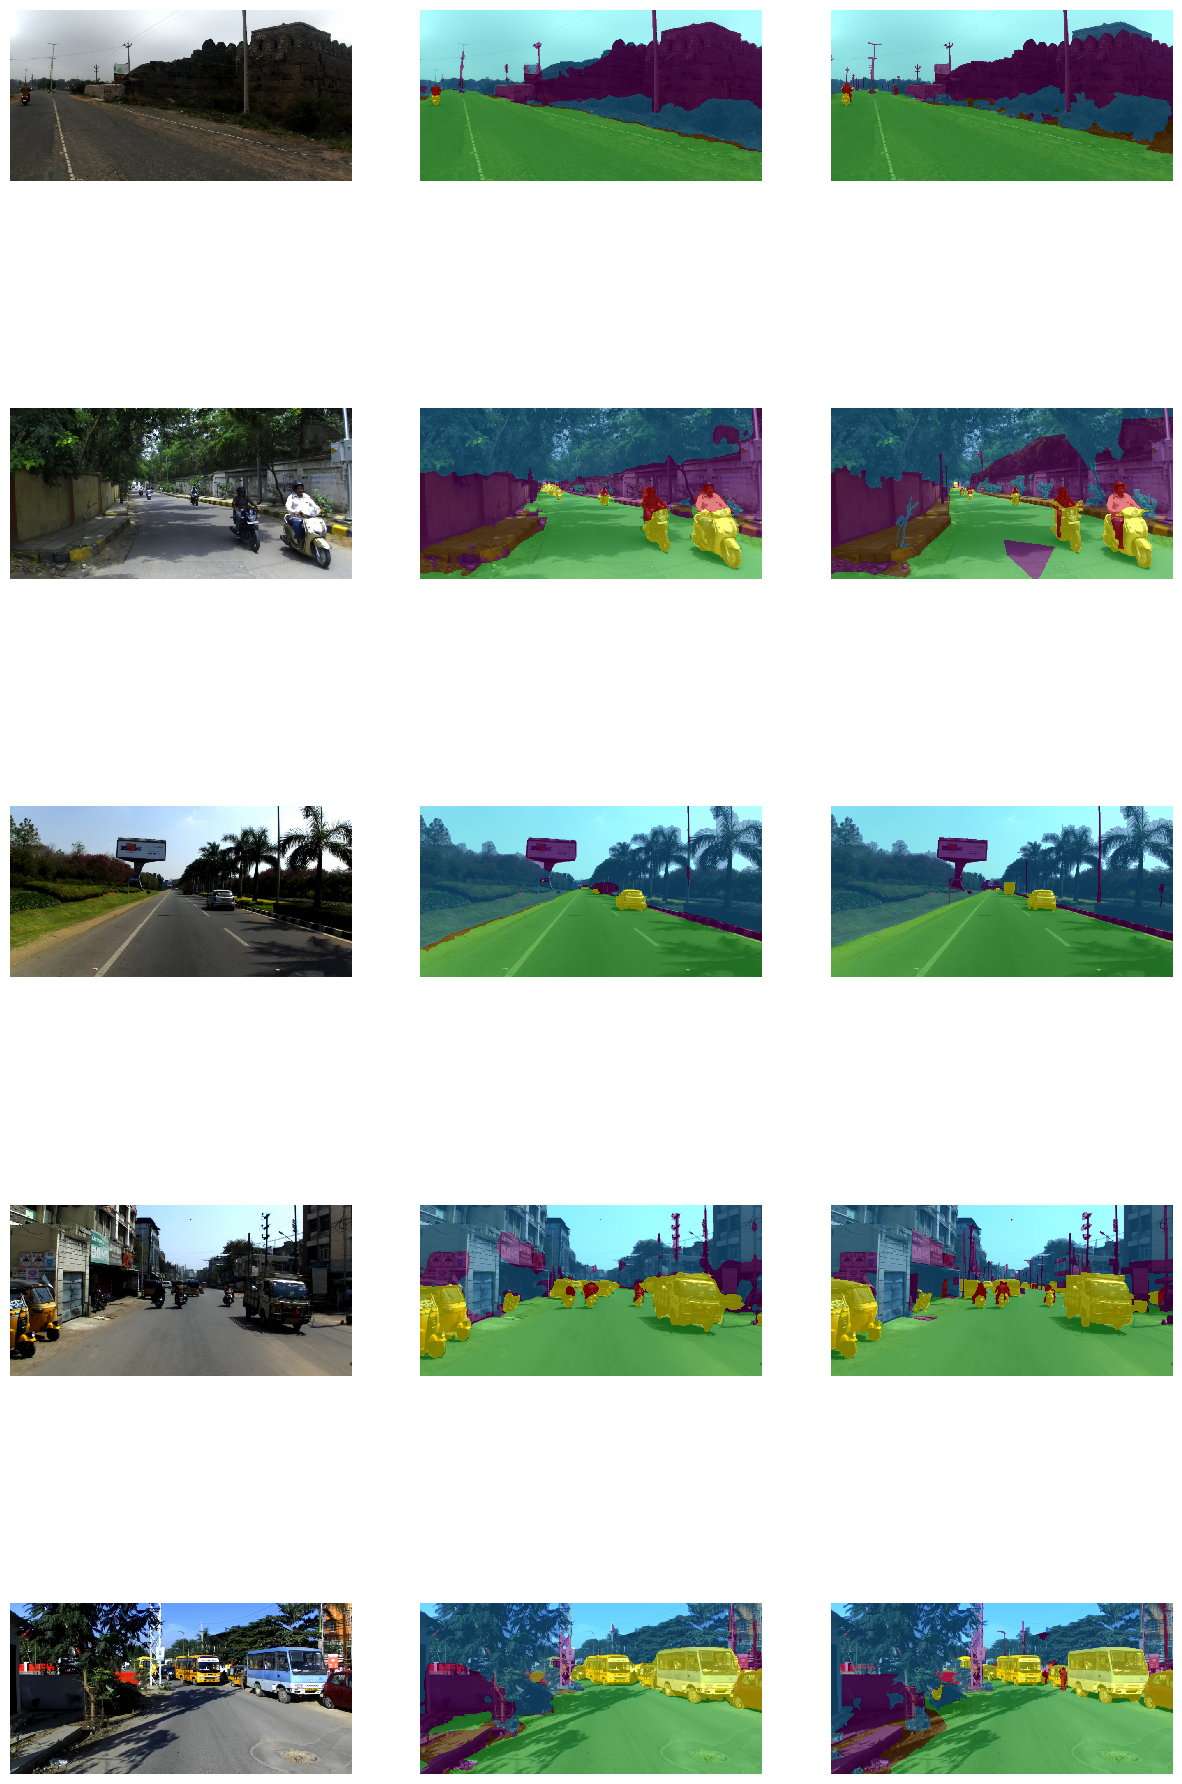

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric         ┃        DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       max_test_mIoU        │     0.6924731731414795     │
│       test_accuracy        │     0.7648887634277344     │
│  test_accuracy_teach_even  │     0.7869219183921814     │
│  test_accuracy_teach_odd   │     0.7869219183921814     │
│      test_dice_score       │     0.7847027778625488     │
│ test_dice_score_teach_even │     0.7968606352806091     │
│ test_dice_score_teach_odd  │     0.7968606352806091     │
│         test_loss          │     0.3154062330722809     │
│    test_loss_teach_even    │     0.2963060438632965     │
│    test_loss_teach_odd     │     0.2963060140609741     │
│         test_mIoU          │     0.6806695461273193     │
│    test_mIoU_teach_even    │     0.6924731731414795     │
│    test_mIoU_teach_odd     │     0.6924731731414795     │
│       test_precision       │     0.8200417757034302     │
│ test_precision_teach_even  │     0.8094578981399536     │
│  test_precision_teach_odd  │     0.8094578981399536     │
│        test_recall         │     0.7648887634277344     │
│   test_recall_teach_even   │     0.7869219183921814     │
│   test_recall_teach_odd    │     0.7869219183921814     │
└────────────────────────────┴────────────────────────────┘

[{'test_loss': 0.3154062330722809,
  'test_mIoU': 0.6806695461273193,
  'test_precision': 0.8200417757034302,
  'test_recall': 0.7648887634277344,
  'test_accuracy': 0.7648887634277344,
  'test_dice_score': 0.7847027778625488,
  'test_loss_teach_even': 0.2963060438632965,
  'test_mIoU_teach_even': 0.6924731731414795,
  'test_precision_teach_even': 0.8094578981399536,
  'test_recall_teach_even': 0.7869219183921814,
  'test_accuracy_teach_even': 0.7869219183921814,
  'test_dice_score_teach_even': 0.7968606352806091,
  'test_loss_teach_odd': 0.2963060140609741,
  'test_mIoU_teach_odd': 0.6924731731414795,
  'test_precision_teach_odd': 0.8094578981399536,
  'test_recall_teach_odd': 0.7869219183921814,
  'test_accuracy_teach_odd': 0.7869219183921814,
  'test_dice_score_teach_odd': 0.7968606352806091,
  'max_test_mIoU': 0.6924731731414795}]

In [65]:
# trainer.test(lit_model_b1, test_loader, ckpt_path="/kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_416x832_mu5_adaptclassmix-epoch=78-max_val_mIoU=0.68492.ckpt")

In [54]:
!zip -r /kaggle/working/lightning_logs.zip /kaggle/working/efficientvit/lightning_logs

  adding: kaggle/working/efficientvit/lightning_logs/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv/version_0/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv/version_0/hparams.yaml (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv/version_0/events.out.tfevents.1725451003.7f07db93c68e.34.0 (deflated 75%)


In [55]:
!zip -r /kaggle/working/checkpoints.zip /kaggle/working/checkpoints

  adding: kaggle/working/checkpoints/ (stored 0%)
  adding: kaggle/working/checkpoints/last.ckpt (deflated 8%)
  adding: kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8_laplacewght_data2_lab1_8_416x832_mu5_15supv-epoch=00-max_val_mIoU=0.70883.ckpt (deflated 8%)
